# Task 2 — native tumor-mask and displaced-control occlusion

**Quick check:** leave `PROFILE = 'smoke'` and choose **Run all**. This runs a
self-contained CPU test using 72 synthetic native MAT images, 36 synthetic
patients, both feature paths, two outer folds and all four occlusion comparisons.
It generates and freezes its own **synthetic** Task 4 fixtures when needed.
Smoke outputs are engineering checks and must never be reported as MRI results.

**Real experiment:** set `PROFILE = 'paper'`, match `TASK4_RUN_NAME` to the
completed Task 4 run, and set `TASK4_RESULTS_DIR` to its folder if needed.
Real inference requires the complete Task 4 artifacts, including trained fold
bundles, and the native Figshare MAT images. Saved notebook cell outputs do not
contain those files. No real patient model is retrained by this notebook.

The four comparisons are **Coherent5**, **Passive5**, **QuadraticLift_LR** and
**SelectedClassical**. Each feature representation is reported separately.
Native masks are translated without wrapping, clipping, tumor overlap or area
changes. Placement uses image/mask information only. Effects first average
slices within each patient and pair complete patients/linked clusters and seeds.

**Repairs:** standalone smoke fixtures; optional PyTorch for CPU checks; explicit
artifact and coverage validation; stale-cache regeneration; finite bootstrap
sampling for small sensitivity subsets; final-cell CSV recovery; atomic summary
writes and safe reruns. The Task 4 prediction equations and clean-image feature
preprocessing remain compatible with the original engine signature.

## 1. Configuration — start here

The delivered notebook defaults to **smoke** so **Run all** works without another
notebook, GPU, MRI download or saved Task 4 models. Switch to **paper** only when
you have the real Task 4 files. Environment variables can override these settings.
After changing the profile, rerun from this cell. Smoke and paper have separate
run names, output folders and checks.

In [1]:
import os
from pathlib import Path

PROFILE = os.getenv('MRI_PROFILE', 'smoke').strip().lower()  # @param ['smoke','paper']
USE_DRIVE = os.getenv('MRI_USE_DRIVE', '1') == '1'  # @param {type:'boolean'}
RESULTS_ROOT = os.getenv('MRI_RESULTS_ROOT', '')
CACHE_ROOT = os.getenv('MRI_CACHE_ROOT', '')
RUN_NAME = os.getenv('MRI_RUN_NAME', PROFILE + '_v1')
TASK4_RUN_NAME = os.getenv('MRI_TASK4_RUN_NAME', PROFILE + '_v1')
TASK4_RESULTS_DIR = os.getenv('MRI_TASK4_RESULTS_DIR', '')
FIGSHARE_ROOT = os.getenv('MRI_FIGSHARE_ROOT', '')
LEGACY_MANIFEST_CSV = os.getenv('MRI_LEGACY_MANIFEST_CSV', '')
SMOKE_AUTO_BUILD_TASK4 = os.getenv('MRI_SMOKE_AUTO_BUILD_TASK4', '1') == '1'
AUDIT_NEAR = True
SPLIT_SEED = 20261023
CLASSES = ['glioma', 'meningioma', 'pituitary']
K = len(CLASSES)
CFG = dict(outer_folds=5, inner_folds=3, seeds=[13,29,47,71,101], epochs=40,
    patience=8, batch=128, feature_batch=32, slice_cap=8,
    learning_rates=[.01,.05], C_grid=[.03,.3,3.,30.], bootstrap=3000)
if PROFILE == 'smoke':
    CFG.update(outer_folds=2, inner_folds=2, seeds=[13], epochs=2, patience=2,
        batch=64, slice_cap=2, learning_rates=[.03], C_grid=[1.], bootstrap=50)
    USE_DRIVE = False
elif PROFILE != 'paper':
    raise ValueError("PROFILE must be 'smoke' or 'paper'.")
for key, value in [('RUN_NAME', RUN_NAME), ('TASK4_RUN_NAME', TASK4_RUN_NAME)]:
    if not value or value in {'.', '..'} or '/' in value or '\\' in value or value.strip() != value:
        raise ValueError(key + ' must be a simple, nonempty directory name.')
VIEWS = ['pixels32', 'resnet18']
TASK_ID = 2
ENGINE_SIGNATURE = '62c219a9695bb45f9faced3cf75413ba3e3b4eb8478bdcb463e6a15dc2b0c234'
OCCLUSION_IMPLEMENTATION = 'task2-occlusion-repair-2.0'
print('Profile:', PROFILE, '| run:', RUN_NAME)
if PROFILE == 'smoke':
    print('SYNTHETIC ENGINEERING CHECK — not real MRI results.')

Profile: smoke | run: smoke_v1
SYNTHETIC ENGINEERING CHECK — not real MRI results.


## 2. Runtime dependencies

Missing helper packages are installed in the active Python environment. Existing
packages are retained. Smoke mode uses NumPy for its circuit simulator and a
deterministic random feature projection; it does not require PyTorch. Paper mode
uses the matching PyTorch/Torchvision pair for frozen ResNet18 features. In Colab,
enable a GPU for the paper feature path if available.

In [2]:
import os, sys, subprocess, importlib.util, importlib.metadata
from pathlib import Path

requirements = {
    'numpy':'numpy>=1.26,<3', 'pandas':'pandas>=2.2,<4', 'scipy':'scipy>=1.13,<2',
    'sklearn':'scikit-learn>=1.5,<2', 'matplotlib':'matplotlib>=3.8,<4',
    'PIL':'Pillow>=10,<13', 'h5py':'h5py>=3.10,<4',
    'skimage':'scikit-image>=0.23,<1', 'imagehash':'ImageHash>=4.3,<5',
    'joblib':'joblib>=1.3,<2', 'requests':'requests>=2.31,<3',
    'tqdm':'tqdm>=4.66,<5', 'tabulate':'tabulate>=0.9,<1',
    'IPython':'ipython>=8,<10', 'threadpoolctl':'threadpoolctl>=3,<4',
}
missing = [spec for module,spec in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing:
    print('Installing missing helpers:', ', '.join(missing))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *missing])
    importlib.invalidate_caches()
if PROFILE == 'paper':
    torch_missing = [name for name in ['torch', 'torchvision']
                     if importlib.util.find_spec(name) is None]
    if torch_missing:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *torch_missing])
        importlib.invalidate_caches()
    try:
        import torch, torchvision
    except (ImportError, RuntimeError, OSError, AttributeError) as exc:
        raise RuntimeError('PyTorch/Torchvision cannot load together. In Colab, restart a fresh '
                           'runtime with its matching preinstalled pair, then Run all.') from exc
    print('torch:', torch.__version__, '| torchvision:', torchvision.__version__,
          '| CUDA:', torch.cuda.is_available())
else:
    print('CPU smoke dependencies ready; no PyTorch or ImageNet weights required.')
print('Python:', sys.version.split()[0])

CPU smoke dependencies ready; no PyTorch or ImageNet weights required.
Python: 3.12.14


### Native data and paired statistics 1

Utilities: `json_default, canonical_json, digest`.

In [3]:
## Imports and reproducibility
import os, sys, json, math, time, random, hashlib, platform, copy, zipfile, shutil, warnings
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import scipy.io
from scipy.fft import dctn
from scipy.special import softmax, logsumexp
from scipy.optimize import minimize_scalar
from scipy.ndimage import binary_fill_holes, binary_erosion, distance_transform_edt
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, confusion_matrix, classification_report
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import h5py, joblib, requests
from threadpoolctl import threadpool_limits
_THREAD_LIMITER=threadpool_limits(limits=min(4,os.cpu_count() or 1))
from tqdm.auto import tqdm
from IPython.display import display, Markdown

VERSION = 'faculty-revision-1.0'
def json_default(v):
    if isinstance(v, Path): return str(v)
    if isinstance(v, (np.integer, np.floating, np.bool_)): return v.item()
    if isinstance(v, np.ndarray): return v.tolist()
    raise TypeError(type(v).__name__)
def canonical_json(v): return json.dumps(v, sort_keys=True, default=json_default, allow_nan=False)
def digest(v): return hashlib.sha256(canonical_json(v).encode()).hexdigest()
def write_json(path, v):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp'); tmp.write_text(json.dumps(v,indent=2,default=json_default),encoding='utf-8'); tmp.replace(path)
def file_hash(path, algorithm='sha256'):
    h=hashlib.new(algorithm)
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''): h.update(b)
    return h.hexdigest()
def atomic_joblib(v,path):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True); tmp=path.with_name(path.name+'.tmp')
    joblib.dump(v,tmp,compress=3); tmp.replace(path)
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    if 'torch' in sys.modules:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark=False; torch.backends.cudnn.deterministic=True
        torch.use_deterministic_algorithms(True,warn_only=True)
def savefig(fig, name):
    OUT.mkdir(parents=True, exist_ok=True)
    try:
        fig.tight_layout()
        fig.savefig(OUT/(name+'.png'), dpi=180, bbox_inches='tight')
        plt.show()
    finally:
        plt.close(fig)
def metric(y,p):
    y=np.asarray(y,int); p=np.asarray(p,float)
    assert p.shape==(len(y),K) and np.isfinite(p).all()
    assert np.allclose(p.sum(1),1,atol=1e-6)
    pred=p.argmax(1)
    ans=dict(accuracy=float(accuracy_score(y,pred)),balanced_accuracy=float(np.mean([np.mean(pred[y==c]==c) for c in np.unique(y)])),
             macro_f1=float(f1_score(y,pred,labels=np.arange(K),average='macro',zero_division=0)),
             nll=float(-np.log(np.clip(p[np.arange(len(y)),y],1e-15,1)).mean()))
    if len(np.unique(y))!=K:
        ans['macro_auc']=float('nan')  # AUC is undefined when a subset omits a class.
    else:
        try: ans['macro_auc']=float(roc_auc_score(y,p,multi_class='ovr',average='macro',labels=np.arange(K)))
        except ValueError: ans['macro_auc']=float('nan')
    return ans

def aggregate(frame, indices, p):
    sub=frame.iloc[np.asarray(indices)][['patient_id','label_id']].copy().reset_index(drop=True)
    for j in range(K): sub[f'p{j}']=p[:,j]
    assert sub.groupby('patient_id').label_id.nunique().max()==1
    return sub.groupby('patient_id',sort=True).agg({'label_id':'first',**{f'p{j}':'mean' for j in range(K)}}).reset_index()
def pcols(table): return table[[f'p{j}' for j in range(K)]].to_numpy(float)
def patient_weights(frame,idx):
    sub=frame.iloc[idx]; w=1/sub.patient_id.map(sub.patient_id.value_counts()).to_numpy(float)
    # Equal total mass for every class, and every patient within a class.
    for y in range(K): w[sub.label_id.to_numpy()==y]/=w[sub.label_id.to_numpy()==y].sum()
    return w/w.mean()

### Native data and paired statistics 2

Utilities: `balanced_slice_weights, stratified_resample, f1_fast`.

In [4]:
def balanced_slice_weights(y):
    n=np.bincount(np.asarray(y,int),minlength=K); return len(y)/(K*n)
def stratified_resample(y,rng):
    return np.concatenate([rng.choice(np.flatnonzero(y==c),size=np.sum(y==c),replace=True) for c in np.unique(y)])
def f1_fast(y,pred):
    cm=np.bincount(K*np.asarray(y,int)+np.asarray(pred,int),minlength=K*K).reshape(K,K)
    den=cm.sum(0)+cm.sum(1); return float(np.divide(2*np.diag(cm),den,out=np.zeros(K),where=den!=0).mean())
def seed_patient_interval(y, a, b=None, n_boot=3000, seed=341, groups=None):
    """Paired seed/patient interval; subset draws retain the observed classes.

    A sensitivity subset can omit an original class. Requiring all K classes in
    that case caused an endless retry loop. Macro F1 still uses all K labels.
    """
    y = np.asarray(y, int)
    a = np.asarray(a, float)
    b = None if b is None else np.asarray(b, float)
    if y.ndim != 1 or not len(y) or a.ndim != 3 or a.shape[1:] != (len(y), K) or not len(a):
        raise ValueError('Expected nonempty y and predictions shaped [seed, patient, class].')
    if not np.isfinite(a).all() or (b is not None and (b.shape != a.shape or not np.isfinite(b).all())):
        raise ValueError('Paired predictions must be finite and have identical shapes.')
    if int(n_boot) < 2:
        raise ValueError('At least two bootstrap draws are required.')
    pred_a = a.argmax(2)
    pred_b = None if b is None else b.argmax(2)
    def statistic(si, ii):
        return float(np.mean([f1_fast(y[ii], pred_a[s,ii]) -
            (0 if pred_b is None else f1_fast(y[ii], pred_b[s,ii])) for s in si]))
    rng = np.random.default_rng(seed)
    all_s = np.arange(len(a)); all_i = np.arange(len(y))
    estimate = statistic(all_s, all_i); fixed = []; joint = []
    if groups is not None:
        group_array = np.asarray(groups)
        if group_array.shape != y.shape or pd.isna(group_array).any():
            raise ValueError('One nonmissing cluster ID is required per patient.')
        ug = np.unique(group_array)
        members = [np.flatnonzero(group_array==g) for g in ug]
        n_classes = len(np.unique(y))
        def draw():
            for _attempt in range(2000):
                ii = np.concatenate([members[j] for j in rng.integers(0,len(ug),len(ug))])
                if len(np.unique(y[ii])) == n_classes:
                    return ii
            raise RuntimeError('Unable to draw a linked-cluster bootstrap retaining the observed '
                               'classes after 2,000 attempts; inspect the cluster composition.')
    else:
        def draw():
            return stratified_resample(y, rng)
    for _ in range(int(n_boot)):
        ii = draw()
        fixed.append(statistic(all_s, ii))
        joint.append(statistic(rng.choice(all_s,len(a),replace=True), ii))
    lo, hi = np.quantile(joint,[.025,.975]); fl, fh = np.quantile(fixed,[.025,.975])
    return dict(estimate=estimate, ci_low=float(lo), ci_high=float(hi),
        patient_only_low=float(fl), patient_only_high=float(fh), n_patients=len(y),
        n_seeds=len(a), n_boot=int(n_boot), n_observed_classes=len(np.unique(y)),
        interval_scope='paired seed and patient/linked-cluster resampling conditional on fitted '
        'outer folds; excludes full refitting and site variance; macro F1 uses all original labels')

def holm(values):
    p=np.asarray(values,float); order=np.argsort(p); ans=np.empty(len(p)); running=0.
    for i,j in enumerate(order): running=max(running,(len(p)-i)*p[j]); ans[j]=min(1.,running)
    return ans

def paired_permutation(y,a,b,reps=1999,seed=774):
    rng=np.random.default_rng(seed); observed=np.mean([f1_fast(y,x.argmax(1))-f1_fast(y,z.argmax(1)) for x,z in zip(a,b)])
    extreme=0
    for _ in range(reps):
        swap=rng.integers(0,2,len(y)).astype(bool)
        aa=np.where(swap[None,:,None],b,a); bb=np.where(swap[None,:,None],a,b)
        value=np.mean([f1_fast(y,x.argmax(1))-f1_fast(y,z.argmax(1)) for x,z in zip(aa,bb)])
        extreme+=abs(value)>=abs(observed)-1e-12
    return (extreme+1)/(reps+1)

def package_outputs(out, name):
    target=out.parent/(name+'.zip')
    with zipfile.ZipFile(target,'w',zipfile.ZIP_DEFLATED) as z:
        for p in sorted(out.rglob('*')):
            if p.is_file() and p.suffix not in {'.tmp','.part'}:
                # Large image-model weights remain in the Drive checkpoint folders.
                if name.startswith('Task1_') and p.suffix=='.pt':continue
                z.write(p,p.relative_to(out.parent))
    print('Results bundle:',target)
    return target

### Native data and paired statistics 3

Utilities: `download_file, safe_extract, figshare_files`.

In [5]:
## Verified downloads and native Figshare reader

def download_file(url,path,md5=None):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    if path.is_file() and path.stat().st_size and (not md5 or file_hash(path,'md5')==md5):return path
    tmp=path.with_name(path.name+'.part')
    for attempt in range(4):
        try:
            fresh=url
            if 'figshare.com/' in url:fresh=url+('&' if '?' in url else '?')+'revision_time='+str(time.time_ns())
            with requests.get(fresh,stream=True,timeout=(30,120)) as r:
                r.raise_for_status()
                with open(tmp,'wb') as f:
                    for b in r.iter_content(1024*1024):
                        if b:f.write(b)
            if tmp.stat().st_size==0 or (md5 and file_hash(tmp,'md5')!=md5):raise ValueError('Empty download or publisher checksum mismatch')
            tmp.replace(path); return path
        except (requests.RequestException,OSError,ValueError) as e:
            tmp.unlink(missing_ok=True)
            if attempt==3: raise RuntimeError(f'Download failed for {path.name}. Supply an extracted local dataset root in the configuration.') from e
            time.sleep(min(2**attempt,8))
def safe_extract(archive,root):
    root=Path(root).resolve(); root.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        for item in z.infolist():
            p=(root/item.filename).resolve()
            if p!=root and root not in p.parents:raise ValueError('Unsafe ZIP member')
            if (item.external_attr>>16)&0o170000==0o120000:raise ValueError('Symlink in ZIP')
        z.extractall(root)
def figshare_files():
    if FIGSHARE_ROOT:
        root=Path(FIGSHARE_ROOT).expanduser().resolve()
        if not root.is_dir():raise FileNotFoundError(root)
    else:
        root=CACHE/'figshare_1512427_v8'; root.mkdir(parents=True,exist_ok=True)
        meta=root/'publisher_metadata.json'
        try:
            r=requests.get('https://api.figshare.com/v2/articles/1512427/versions/8',timeout=(30,90));r.raise_for_status();article=r.json();write_json(meta,article)
        except (requests.RequestException,ValueError):
            if not meta.exists():raise
            article=json.loads(meta.read_text());print('Using cached version 8 metadata with checksum validation.')
        for f in article['files']:
            if not f['name'].lower().endswith('.zip'):continue
            archive=download_file(f['download_url'],root/Path(f['name']).name,f.get('computed_md5') or f.get('supplied_md5'))
            marker=archive.with_suffix('.extracted.json'); sha=file_hash(archive)
            with zipfile.ZipFile(archive) as z: members=[x for x in z.infolist() if not x.is_dir()]
            ok=marker.exists() and json.loads(marker.read_text()).get('sha256')==sha
            ok=ok and all((root/x.filename).is_file() and (root/x.filename).stat().st_size==x.file_size for x in members)
            if not ok:safe_extract(archive,root);write_json(marker,{'sha256':sha})
    paths=sorted(p for p in root.rglob('*.mat') if p.stem.isdigit())
    if not paths: raise FileNotFoundError('No numbered native cjdata MAT files. Use the original Figshare release, not a JPG conversion.')
    return root,paths

def decode_pid(value):
    if isinstance(value,bytes): return value.decode().strip()
    if isinstance(value,str):return value.strip()
    a=np.asarray(value).ravel()
    if a.dtype.kind in 'US':return ''.join(x.decode() if isinstance(x,bytes) else str(x) for x in a).strip()
    if a.dtype.kind in 'iuf' and len(a)>1:return ''.join(chr(int(x)) for x in a if int(x)).strip()
    return ''.join(str(x) for x in a).strip()


### Native data and paired statistics 4

Utilities: `read_mat, normalize_image, resize_float`.

In [6]:
def read_mat(path):
    if h5py.is_hdf5(path):
        with h5py.File(path,'r') as f:
            g=f['cjdata']
            def value(key):
                v=g[key]
                if h5py.check_dtype(ref=v.dtype) is not None:
                    refs=np.asarray(v).ravel()
                    if len(refs)!=1:raise ValueError('Unexpected multiple MATLAB references')
                    return np.asarray(f[refs[0]])
                return np.asarray(v)
            image=value('image').T; rawmask=value('tumorMask').T if 'tumorMask' in g else None
            pid=decode_pid(value('PID')); label=int(value('label').squeeze()); fields=list(g.keys())
    else:
        g=scipy.io.loadmat(path,simplify_cells=True)['cjdata']
        image=np.asarray(g['image']);rawmask=np.asarray(g['tumorMask']) if 'tumorMask' in g else None
        pid=decode_pid(g['PID']);label=int(np.asarray(g['label']).squeeze());fields=list(g)
    if label not in [1,2,3] or not pid or image.ndim!=2 or not np.isfinite(image).all():raise ValueError('Invalid cjdata '+str(path))
    if rawmask is None:mask=None
    else:
        if rawmask.shape!=image.shape or not np.isfinite(rawmask).all():raise ValueError('Mask shape or numeric error '+str(path))
        if not set(np.unique(rawmask)).issubset({0,1,False,True}):raise ValueError('Mask must be binary '+str(path))
        mask=rawmask.astype(bool)
    return image,mask,'cheng::'+pid,{1:'meningioma',2:'glioma',3:'pituitary'}[label],fields

def normalize_image(x):
    x=np.asarray(x,np.float32);lo,hi=np.percentile(x,[1,99]);return np.clip((x-lo)/max(float(hi-lo),1e-6),0,1)
def resize_float(x,side):return np.asarray(Image.fromarray(np.asarray(x,np.float32)).resize((side,side),Image.Resampling.BILINEAR),np.float32)

def fixture_figshare():
    root=CACHE/'synthetic_native';root.mkdir(parents=True,exist_ok=True)
    rng=np.random.default_rng(811); paths=[]; yy,xx=np.mgrid[:40,:40]
    for c,label in enumerate(['glioma','meningioma','pituitary']):
        for patient in range(12):
            for sl in range(2):
                brain=((xx-20)/16)**2+((yy-20)/18)**2<1
                mask=(xx-(12+5*c))**2+(yy-19)**2<(4+c)**2
                x=np.maximum(0,rng.normal(.08,.03,(40,40)))+brain*.25+mask*.4
                image=(np.clip(x,0,1)*65535).astype(np.uint16)
                p=root/f'{c*1000+patient*2+sl+1}.mat'
                pid=f'synthetic_{label}_{patient:03d}'
                if p.is_file():
                    check=read_mat(p)
                    if check[2]=='cheng::'+pid and check[3]==label and np.array_equal(check[0],image) and np.array_equal(check[1],mask):
                        paths.append(p);continue
                # Mix both native MAT reader paths, including HDF5 MATLAB orientation.
                lab={'meningioma':1,'glioma':2,'pituitary':3}[label]
                if sl%2==0:
                    scipy.io.savemat(p,{'cjdata':dict(image=image,tumorMask=mask.astype(np.uint8),PID=pid,label=lab)})
                else:
                    with h5py.File(p,'w') as f:
                        g=f.create_group('cjdata');g['image']=image.T;g['tumorMask']=mask.T.astype(np.uint8)
                        g['PID']=np.array([ord(t) for t in pid],np.uint16)[:,None];g['label']=np.array([[lab]])
                paths.append(p)
    return root,sorted(paths)

### Native data and paired statistics 5

Utilities: `native_manifest, DSU, BKTree`.

In [7]:
def native_manifest():
    root,paths=fixture_figshare() if PROFILE=='smoke' else figshare_files()
    records=[]
    for p in tqdm(paths,desc='Validate native images, IDs and masks'):
        x,m,pid,label,fields=read_mat(p)
        records.append(dict(sample_id=p.stem,relative_path=p.relative_to(root).as_posix(),path=str(p.resolve()),
            patient_id=pid,label=label,label_id=CLASSES.index(label),height=x.shape[0],width=x.shape[1],
            mask_present=m is not None,mask_pixels=int(m.sum()) if m is not None else 0,
            file_sha256=file_hash(p),pixel_sha256=hashlib.sha256(str((x.shape,str(x.dtype))).encode()+x.tobytes()).hexdigest()))
    frame=pd.DataFrame(records).sort_values('relative_path').reset_index(drop=True)
    assert frame.sample_id.is_unique and frame.groupby('patient_id').label_id.nunique().max()==1
    if PROFILE!='smoke':
        assert len(frame)==3064 and frame.patient_id.nunique()==233, 'Wrong/incomplete Figshare release; expected 3,064 slices and 233 patients.'
        assert frame.groupby('label').size().to_dict()=={'glioma':1426,'meningioma':708,'pituitary':930}
    return frame

## Fold construction, EDA and independent frozen features
class DSU:
    def __init__(self,n):self.p=list(range(n))
    def find(self,i):
        while self.p[i]!=i:self.p[i]=self.p[self.p[i]];i=self.p[i]
        return i
    def union(self,a,b):
        a,b=self.find(a),self.find(b)
        if a!=b:self.p[max(a,b)]=min(a,b)
class BKTree:
    def __init__(self):self.root=None
    def add(self,v,i):
        if self.root is None:self.root=[v,[i],{}];return
        n=self.root
        while True:
            d=(n[0]^v).bit_count()
            if d==0:n[1].append(i);return
            if d not in n[2]:n[2][d]=[v,[i],{}];return
            n=n[2][d]
    def query(self,v,r):
        found=[];stack=[] if self.root is None else [self.root]
        while stack:
            n=stack.pop();d=(n[0]^v).bit_count()
            if d<=r:found.extend(n[1])
            stack.extend(child for k,child in n[2].items() if d-r<=k<=d+r)
        return found

def patient_duplicate_links(frame):
    # Patient identity is the endpoint; duplicate links only constrain splitting.
    import imagehash
    from skimage.metrics import structural_similarity
    units=sorted(frame.patient_id.unique());lookup={x:i for i,x in enumerate(units)};uf=DSU(len(units));edges=[]
    for _,ids in frame.groupby('pixel_sha256').groups.items():
        ids=list(ids)
        for j in ids[1:]:
            a,b=frame.iloc[ids[0]],frame.iloc[j];uf.union(lookup[a.patient_id],lookup[b.patient_id])
            if a.patient_id!=b.patient_id:edges.append(dict(a=a.sample_id,b=b.sample_id,kind='exact',ssim=1.))
    if AUDIT_NEAR:
        tree=BKTree();thumb=[]; hashes=[]
        for i,row in tqdm(enumerate(frame.itertuples()),total=len(frame),desc='Cross-patient duplicate audit'):
            small=(resize_float(normalize_image(read_mat(row.path)[0]),64)*255).astype(np.uint8)
            h=int(str(imagehash.phash(Image.fromarray(small))),16)
            for j in tree.query(h,3):
                if row.patient_id==frame.iloc[j].patient_id:continue
                s=float(structural_similarity(small,thumb[j],data_range=255))
                if s>=.985:
                    uf.union(lookup[row.patient_id],lookup[frame.iloc[j].patient_id]);edges.append(dict(a=row.sample_id,b=frame.iloc[j].sample_id,kind='near',ssim=s))
            thumb.append(small);hashes.append(h);tree.add(h,i)
    groups={pid:'link_'+digest(sorted(x for x in units if uf.find(lookup[x])==uf.find(lookup[pid])))[:16] for pid in units}
    result=frame.copy();result['split_group']=result.patient_id.map(groups)
    pd.DataFrame(edges,columns=['a','b','kind','ssim']).to_csv(OUT/'cross_patient_duplicate_links.csv',index=False)
    return result


### Native data and paired statistics 6

Utilities: `grouped_patient_folds, make_nested_plan, idx_for`.

In [8]:
def grouped_patient_folds(frame,patient_ids,n,seed):
    tab=frame[frame.patient_id.isin(patient_ids)][['patient_id','label_id','split_group']].drop_duplicates().sort_values('patient_id').reset_index(drop=True)
    if (tab.groupby('label_id').size()<n).any():raise ValueError('Not enough patients per class for requested folds')
    if tab.split_group.nunique()==len(tab):
        splitter=StratifiedKFold(n_splits=n,shuffle=True,random_state=seed);iterator=splitter.split(tab,tab.label_id)
    else:
        splitter=StratifiedGroupKFold(n_splits=n,shuffle=True,random_state=seed);iterator=splitter.split(tab,tab.label_id,tab.split_group)
    folds=[]
    for tr,va in iterator:
        a,b=tab.iloc[tr],tab.iloc[va]
        assert not set(a.split_group)&set(b.split_group)
        if set(a.label_id)!=set(range(K)) or set(b.label_id)!=set(range(K)):raise ValueError('Fold lost a class after duplicate grouping; review the linkage audit before changing protocol.')
        folds.append((a.patient_id.tolist(),b.patient_id.tolist()))
    return folds

def make_nested_plan(frame):
    plans=[]
    for fold,(dev,test) in enumerate(grouped_patient_folds(frame,frame.patient_id.unique(),CFG['outer_folds'],SPLIT_SEED)):
        inner=[dict(train_patients=a,valid_patients=b) for a,b in grouped_patient_folds(frame,dev,CFG['inner_folds'],SPLIT_SEED+100+fold)]
        plans.append(dict(fold=fold,development_patients=dev,test_patients=test,inner=inner))
    tests=[p for item in plans for p in item['test_patients']]
    assert len(tests)==len(set(tests))==frame.patient_id.nunique()
    return plans

def idx_for(frame,patients):return np.flatnonzero(frame.patient_id.isin(set(patients)).to_numpy())
def cap_training(frame,indices,seed):
    rng=np.random.default_rng(seed);keep=[]
    for _,s in frame.iloc[indices].groupby('patient_id',sort=True):
        keep.extend(rng.choice(s.index.to_numpy(),min(len(s),CFG['slice_cap']),replace=False))
    return np.asarray(sorted(keep),int)

def dataset_eda(frame):
    counts=pd.DataFrame({'slices':frame.groupby('label').size(),'patients':frame.groupby('label').patient_id.nunique()})
    counts.to_csv(OUT/'eda_class_counts.csv');display(counts)
    fig,axes=plt.subplots(1,3,figsize=(13,3.5));counts.plot.bar(ax=axes[0],rot=25)
    frame.groupby('patient_id').size().plot.hist(bins=20,ax=axes[1]);axes[1].set_title('Slices per patient')
    axes[2].scatter(frame.width,frame.height,s=5,alpha=.3);axes[2].set_title('Native dimensions');savefig(fig,'eda_counts_dimensions')
    fig,axes=plt.subplots(K,3,figsize=(8,K*2.5),squeeze=False)
    for c in range(K):
        for ax,(_,r) in zip(axes[c],frame[frame.label_id==c].head(3).iterrows()):
            x,m,*_=read_mat(r.path);ax.imshow(normalize_image(x),cmap='gray')
            if m is not None and m.any():ax.contour(m,levels=[.5],colors=['lime'],linewidths=.7)
            ax.set_title(CLASSES[c]);ax.axis('off')
    savefig(fig,'eda_native_mask_overlays')

_BACKBONE=None

def resnet_features(images):
    global _BACKBONE
    import torch
    from torchvision import models
    if _BACKBONE is None:
        device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        _BACKBONE=models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        _BACKBONE.fc=torch.nn.Identity();_BACKBONE.eval().to(device)
        for p in _BACKBONE.parameters():p.requires_grad_(False)
    device=next(_BACKBONE.parameters()).device;results=[]
    mean=torch.tensor([.485,.456,.406],device=device)[None,:,None,None]
    std=torch.tensor([.229,.224,.225],device=device)[None,:,None,None]
    with torch.inference_mode():
        for start in range(0,len(images),CFG['feature_batch']):
            batch=np.stack([resize_float(im,224) for im in images[start:start+CFG['feature_batch']]])
            x=torch.as_tensor(batch[:,None],device=device).repeat(1,3,1,1);x=(x-mean)/std
            results.append(_BACKBONE(x).float().cpu().numpy())
    return np.concatenate(results)


### Native data and paired statistics 7

Utilities: `feature_arrays`.

In [9]:
def feature_arrays(frame):
    identity=digest(dict(images=frame[['sample_id','file_sha256']].to_dict('records'),version=VERSION,fixture=PROFILE=='smoke',resnet='IMAGENET1K_V1',normalization='percentile1_99',resize='bilinear_direct'))
    path=CACHE/f'figshare_features_{identity[:16]}.joblib'
    if path.exists():return joblib.load(path)
    ims=[normalize_image(read_mat(r.path)[0]) for r in tqdm(frame.itertuples(),total=len(frame),desc='Per-image normalization')]
    pix=np.stack([resize_float(im,32).ravel() for im in ims]).astype(np.float64)
    if PROFILE=='smoke':
        # No network/ImageNet weights during synthetic code tests. Never scientific results.
        projection=np.random.default_rng(411).normal(size=(pix.shape[1],64))/np.sqrt(pix.shape[1]);rich=pix@projection
    else:rich=resnet_features(ims).astype(np.float64)
    ans=dict(pixels32=pix,resnet18=rich,feature_identity=identity);atomic_joblib(ans,path);return ans


## 3 Output location

In [10]:
BASE = Path('/content') if Path('/content').is_dir() else Path.cwd()
if USE_DRIVE:
    try:
        _in_colab = importlib.util.find_spec('google.colab') is not None
    except (ModuleNotFoundError, ValueError):
        _in_colab = False
    if _in_colab:
        from google.colab import drive
        drive.mount('/content/drive', force_remount=False)
        if not Path('/content/drive/MyDrive').is_dir():
            raise RuntimeError('Drive did not mount. Reconnect it or set USE_DRIVE=False.')
        if not RESULTS_ROOT:
            RESULTS_ROOT = '/content/drive/MyDrive/Brain_MRI_Faculty_Revision'
    else:
        print('Outside Colab: using the configured/local results folder.')
ROOT = (Path(RESULTS_ROOT).expanduser() if RESULTS_ROOT else BASE/'Brain_MRI_Faculty_Revision').resolve()
CACHE = (Path(CACHE_ROOT).expanduser() if CACHE_ROOT else BASE/'brain_mri_faculty_cache').resolve()
OUT = ROOT / 'task2' / RUN_NAME
OUT.mkdir(parents=True, exist_ok=True); CACHE.mkdir(parents=True, exist_ok=True)
versions = {}
for name in ['numpy','pandas','scipy','scikit-learn','torch','torchvision','h5py',
             'ImageHash','scikit-image','matplotlib','joblib']:
    try:
        versions[name] = importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        versions[name] = 'not installed (optional for smoke)' if name in {'torch','torchvision'} else 'not installed'
write_json(OUT/'environment.json', dict(python=sys.version, versions=versions,
    engine_signature=ENGINE_SIGNATURE, implementation=OCCLUSION_IMPLEMENTATION, profile=PROFILE))
freeze = subprocess.run([sys.executable,'-m','pip','freeze'], text=True, capture_output=True)
(OUT/'environment_freeze.txt').write_text(freeze.stdout or freeze.stderr, encoding='utf-8')
print('Outputs:', OUT)
if PROFILE == 'smoke':
    print('SYNTHETIC ENGINEERING CHECK — not MRI results.')

Outputs: /workspace/scratch/a938777b717e/work/smoke_results/task2/smoke_v1
SYNTHETIC ENGINEERING CHECK — not MRI results.


### Saved original-model prediction support 1

Utilities: `angle_gate, apply_gate, cnot_permutation`.

In [11]:
## Exact original norm-fusion circuits
QUANTUM_MODELS = ["Amplitude4","Passive5","Coherent5","ConstantNorm5","ShuffledNorm5"]
def angle_gate(axis,theta):
    if axis=="Z":
        diagonal=np.exp(np.array([-0.5j,0.5j])*theta)
        gate=np.diag(diagonal); derivative=np.diag(diagonal*np.array([-0.5j,0.5j]))
    elif axis=="Y":
        c,s=np.cos(theta/2),np.sin(theta/2)
        gate=np.array([[c,-s],[s,c]],complex)
        derivative=0.5*np.array([[-s,-c],[c,-s]],complex)
    else: raise KeyError(axis)
    return gate,derivative
def apply_gate(state,gate,wire,n):
    shape=(len(state),2**wire,2,2**(n-wire-1))
    return np.einsum("ab,mlbr->mlar",gate,state.reshape(shape),optimize=True).reshape(state.shape)
def cnot_permutation(n,control,target):
    ids=np.arange(2**n)
    return ids ^ (((ids>>(n-1-control))&1)<<(n-1-target))
def circuit_ops(model,weights):
    norm=model!="Amplitude4"
    ops=[]
    if norm: ops.append(("CNOT",4,0,None))
    for layer in range(2):
        for wire in range(4):
            for j,axis in enumerate(["Z","Y","Z"]):
                ops.append((axis,wire,float(weights[layer,wire,j]),(layer,wire,j)))
        for wire in range(4): ops.append(("CNOT",wire,(wire+1)%4,None))
        if norm:
            if model in {"Coherent5","ConstantNorm5","ShuffledNorm5"}:
                ops.append(("H",4,None,None))
            ops.append(("CNOT",4,layer%4,None))
    return ops
def lift_state(direction,angle,model):
    if model=="Amplitude4": return np.asarray(direction,complex)
    if model=="ConstantNorm5": angle=np.full(len(direction),np.pi/2)
    anc=np.column_stack([np.cos(angle/2),np.sin(angle/2)])
    return (np.asarray(direction)[:,:,None]*anc[:,None,:]).reshape(len(direction),32).astype(complex)
def readout_signs(n,k):
    ids=np.arange(2**n)
    return np.stack([1-2*((ids>>(n-1-wire))&1) for wire in range(k)])
def forward_state(initial,weights,model,save=False):
    n=4 if model=="Amplitude4" else 5
    state=np.asarray(initial,complex); history=[]
    for axis,wire,value,index in circuit_ops(model,weights):
        before=state
        if axis=="CNOT":
            permutation=cnot_permutation(n,wire,value)
            state=state[:,permutation]
            if save: history.append(("CNOT",permutation,None,None,None))
        else:
            gate,derivative=(np.array([[1,1],[1,-1]],complex)/np.sqrt(2),None) if axis=="H" else angle_gate(axis,value)
            state=apply_gate(state,gate,wire,n)
            if save: history.append((axis,wire,gate,derivative,(index,before)))
    return state,history
def quantum_logits(direction,angle,weights,model,k):
    initial=lift_state(direction,angle,model)
    state,_=forward_state(initial,weights,model)
    n=4 if model=="Amplitude4" else 5
    return np.abs(state)**2 @ readout_signs(n,k).T
def quantum_loss_gradient(direction,angle,y,weights,model,k,sample_weight):
    initial=lift_state(direction,angle,model)
    state,history=forward_state(initial,weights,model,save=True)
    n=4 if model=="Amplitude4" else 5
    signs=readout_signs(n,k); logits=np.abs(state)**2@signs.T
    p=softmax(logits,axis=1)
    # training_weights has global mean one: batch-size scaling is an unbiased
    # minibatch estimate of the common full weighted cross-entropy objective.
    w=np.asarray(sample_weight,float)/len(y)
    loss=float(np.sum(w*(logsumexp(logits,axis=1)-logits[np.arange(len(y)),y])))
    g=(p-np.eye(k)[y])*w[:,None]
    adjoint=state*(g@signs)
    gradient=np.zeros_like(weights)
    for axis,wire,gate,derivative,payload in reversed(history):
        if axis=="CNOT":
            adjoint=adjoint[:,wire]
        else:
            index,before=payload
            if derivative is not None:
                tangent=apply_gate(before,derivative,wire,n)
                gradient[index]=2*np.real(np.sum(adjoint.conj()*tangent))
            adjoint=apply_gate(adjoint,gate.conj().T,wire,n)
    return loss,gradient

def direction_norm(z):
    norm=np.linalg.norm(z,axis=1);d=np.divide(z,norm[:,None],out=np.zeros_like(z),where=norm[:,None]>1e-12)
    d[norm<=1e-12,0]=1
    return d,np.log(np.maximum(norm,1e-12))


### Saved original-model prediction support 2

Utilities: `prep_fit, prep_transform, classic_input`.

In [12]:
def prep_fit(raw,idx,view):
    # pixels32 follows the actual original notebook (32, despite the manuscript's 64).
    scaler=StandardScaler().fit(raw[idx]) if view=='resnet18' else None
    xx=scaler.transform(raw[idx]) if scaler is not None else raw[idx]
    n=min(16,len(idx),xx.shape[1]);pca=PCA(n_components=n,svd_solver='full').fit(xx)
    z=pca.transform(xx);z=np.pad(z,((0,0),(0,16-n)))
    _,ln=direction_norm(z);limits=np.quantile(ln,[.05,.95]);r0=max(float(np.median(np.linalg.norm(z,axis=1))),1e-8)
    if limits[1]-limits[0]<1e-6:limits[1]=limits[0]+1
    return dict(scaler=scaler,pca=pca,pca_rank=n,norm_limits=limits,r0=r0,view=view,
                fit_index_sha256=digest(np.asarray(idx,int).tolist()))
def prep_transform(prep,raw):
    x=prep['scaler'].transform(raw) if prep['scaler'] is not None else raw
    z=prep['pca'].transform(x);z=np.pad(z,((0,0),(0,16-z.shape[1])))
    d,ln=direction_norm(z);lo,hi=prep['norm_limits'];angle=np.pi*np.clip((ln-lo)/max(hi-lo,1e-6),0,1)
    return dict(z=z,direction=d,lognorm=ln,angle=angle,raw=raw)
def classic_input(data,name):
    if name in ['PCA_LR','PCA_SVM','PCA_RF']:return data['z']
    if name=='ResNet18_Probe':return data['raw']
    if name=='QuadraticDirection_LR':phi=data['direction']
    elif name=='QuadraticLift_LR':phi=lift_state(data['direction'],data['angle'],'Passive5').real
    else:raise KeyError(name)
    i,j=np.triu_indices(phi.shape[1]);return phi[:,i]*phi[:,j]
def predict_record(rec,data):
    if rec['name'] in QUANTUM_MODELS:
        return quantum_logits(data['direction'],data['angle'],rec['weights'],rec['name'],K)
    x=rec['scaler'].transform(classic_input(data,rec['name']));model=rec['estimator']
    if rec['name']=='PCA_RF':return np.log(np.clip(model.predict_proba(x),1e-12,1))
    v=model.decision_function(x)
    return np.asarray(v,float)
def model_grid(name):
    if name in QUANTUM_MODELS:return [dict(lr=x) for x in CFG['learning_rates']]
    if name=='PCA_RF':return [dict(max_depth=x,min_samples_leaf=2) for x in ([8,None] if PROFILE=='paper' else [6])]
    return [dict(C=x) for x in CFG['C_grid']]


### Saved original-model prediction support 3

Utilities: `fit_record, original_math_checks, model_names`.

In [13]:
def fit_record(name,hp,data,y,w,seed,validation=None,fixed_epochs=None):
    started=time.perf_counter()
    if name not in QUANTUM_MODELS:
        xx=classic_input(data,name);scaler=StandardScaler().fit(xx);xx=scaler.transform(xx)
        if name=='PCA_SVM':model=SVC(kernel='rbf',gamma='scale',decision_function_shape='ovr',**hp)
        elif name=='PCA_RF':model=RandomForestClassifier(n_estimators=200 if PROFILE!='smoke' else 12,n_jobs=2,random_state=seed,**hp)
        else:model=LogisticRegression(max_iter=4000,solver='lbfgs',random_state=seed,**hp)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always');model.fit(xx,y,sample_weight=w)
        return dict(name=name,estimator=model,scaler=scaler,hp=hp,seed=seed,best_epoch=0,history=[],
                    fit_seconds=time.perf_counter()-started,warnings=[str(x.message) for x in caught])
    rng=np.random.default_rng(seed);theta=rng.normal(0,.08,(2,4,3));m=np.zeros_like(theta);v=m.copy()
    best_key=(-np.inf,-np.inf);best=None;best_epoch=0;step=0;stale=0;history=[]
    budget=fixed_epochs if fixed_epochs is not None else CFG['epochs']
    for epoch in range(1,budget+1):
        losses=[];order=rng.permutation(len(y))
        for start in range(0,len(order),CFG['batch']):
            ii=order[start:start+CFG['batch']]
            loss,g=quantum_loss_gradient(data['direction'][ii],data['angle'][ii],y[ii],theta,name,K,w[ii])
            if not np.isfinite(loss) or not np.isfinite(g).all():raise FloatingPointError('Nonfinite circuit fit')
            step+=1;m=.9*m+.1*g;v=.999*v+.001*g*g
            theta-=hp['lr']*(m/(1-.9**step))/(np.sqrt(v/(1-.999**step))+1e-8);losses.append(loss)
        row=dict(epoch=epoch,train_loss=float(np.mean(losses)))
        if validation is not None:
            vd,vframe,vi=validation
            pp=softmax(quantum_logits(vd['direction'],vd['angle'],theta,name,K),axis=1)
            tab=aggregate(vframe,vi,pp);score=metric(tab.label_id.to_numpy(),pcols(tab));key=(score['macro_f1'],-score['nll'])
            row.update(validation_macro_f1=score['macro_f1'],validation_nll=score['nll'])
            if key>best_key:best_key=key;best=theta.copy();best_epoch=epoch;stale=0
            else:stale+=1
        history.append(row)
        if validation is not None and stale>=CFG['patience']:break
    if validation is None:best=theta.copy();best_epoch=budget
    assert best is not None
    return dict(name=name,weights=best,hp=hp,seed=seed,best_epoch=int(best_epoch),history=history,
                fit_seconds=time.perf_counter()-started,warnings=[])

## Circuit checks and nested fitting engine

def original_math_checks():
    rng=np.random.default_rng(19);d=rng.normal(size=(4,16));d/=np.linalg.norm(d,axis=1,keepdims=True)
    a=rng.uniform(.1,2.8,4);w=rng.normal(0,.2,(2,4,3));yy=np.array([0,1,2,0]);records=[]
    for name in ['Amplitude4','Passive5','Coherent5']:
        n=4 if name=='Amplitude4' else 5
        U=forward_state(np.eye(2**n,dtype=complex),w,name)[0].T
        assert np.max(abs(U.conj().T@U-np.eye(len(U))))<1e-10
        phi=lift_state(d,a,name).real;obs=np.stack([np.real(U.conj().T@(s[:,None]*U)) for s in readout_signs(n,K)])
        q=quantum_logits(d,a,w,name,K);lift=np.einsum('ni,kij,nj->nk',phi,obs,phi)
        equiv=float(np.max(abs(q-lift)));assert equiv<1e-10
        _,g=quantum_loss_gradient(d,a,yy,w,name,K,np.ones(4));h=1e-5;ix=(0,1,2);wp=w.copy();wm=w.copy();wp[ix]+=h;wm[ix]-=h
        fd=(quantum_loss_gradient(d,a,yy,wp,name,K,np.ones(4))[0]-quantum_loss_gradient(d,a,yy,wm,name,K,np.ones(4))[0])/(2*h)
        error=abs(fd-g[ix]);assert error<1e-6
        records.append(dict(model=name,unitarity_error=float(np.max(abs(U.conj().T@U-np.eye(len(U))))),quadratic_error=equiv,gradient_error=float(error)))
    return pd.DataFrame(records)

def model_names(view):
    names=['Amplitude4','Passive5','Coherent5','QuadraticLift_LR','QuadraticDirection_LR','PCA_LR','PCA_SVM','PCA_RF']
    if view=='resnet18':names.append('ResNet18_Probe')
    return names


### Saved original-model prediction support 4

Utilities: `nested_fold`.

In [14]:
def nested_fold(frame,features,plan,view):
    fold=plan['fold'];raw=features[view];names=model_names(view)
    folder=OUT/f'{view}/fold_{fold:02d}';folder.mkdir(parents=True,exist_ok=True)
    cache_path=folder/'bundle.joblib'
    identity=digest(dict(protocol=PROTOCOL_SHA,fold=plan,view=view,feature_identity=features['feature_identity']))
    if cache_path.exists():
        bundle=joblib.load(cache_path)
        if bundle['identity']!=identity:raise ValueError('Checkpoint identity mismatch')
        print('Resume completed outer fold',fold,view);return bundle
    # Preprocessing is refitted independently inside every inner training fold.
    contexts=[]
    for inner,s in enumerate(plan['inner']):
        fi=cap_training(frame,idx_for(frame,s['train_patients']),SPLIT_SEED+10000+fold*10+inner)
        vi=idx_for(frame,s['valid_patients']);prep=prep_fit(raw,fi,view)
        contexts.append((fi,vi,prep,prep_transform(prep,raw[fi]),prep_transform(prep,raw[vi])))
    tuned={};candidate_rows=[];all_hist=[]
    for seed in CFG['seeds']:
        tuned[seed]={}
        for name in names:
            options=[]
            for hp in model_grid(name):
                cp=folder/'inner_cache'/f'{name}_s{seed}_{digest(hp)[:10]}.joblib'
                if cp.exists():
                    entry=joblib.load(cp);assert entry['identity']==identity
                else:
                    scores=[];epochs=[];details=[];hist=[]
                    for inner,(fi,vi,prep,fd,vd) in enumerate(contexts):
                        rec=fit_record(name,hp,fd,frame.iloc[fi].label_id.to_numpy(),patient_weights(frame,fi),seed,
                            validation=(vd,frame,vi) if name in QUANTUM_MODELS else None)
                        tab=aggregate(frame,vi,softmax(predict_record(rec,vd),axis=1));s=metric(tab.label_id.to_numpy(),pcols(tab))
                        scores.append(s);epochs.append(rec['best_epoch']);details.append(dict(inner=inner,**s,warnings=rec['warnings']))
                        hist.extend([dict(fold=fold,view=view,seed=seed,model=name,hp=canonical_json(hp),inner=inner,**h) for h in rec['history']])
                    entry=dict(identity=identity,hp=hp,mean_f1=float(np.mean([s['macro_f1'] for s in scores])),
                        mean_nll=float(np.mean([s['nll'] for s in scores])),epochs=epochs,details=details,history=hist)
                    atomic_joblib(entry,cp)
                options.append(entry);all_hist.extend(entry['history'])
                candidate_rows.append(dict(fold=fold,view=view,seed=seed,model=name,hp=canonical_json(hp),inner_macro_f1=entry['mean_f1'],inner_nll=entry['mean_nll']))
            best=sorted(options,key=lambda x:(-x['mean_f1'],x['mean_nll'],canonical_json(x['hp'])))[0]
            tuned[seed][name]=best
            print(f"fold {fold+1}/{CFG['outer_folds']} {view} seed {seed} {name}: inner F1 {best['mean_f1']:.3f}",flush=True)
    classical=[n for n in names if n not in QUANTUM_MODELS]
    family_scores={name:float(np.mean([tuned[s][name]['mean_f1'] for s in CFG['seeds']])) for name in classical}
    selected=sorted(classical,key=lambda n:(-family_scores[n],n))[0]
    # One family for the selection strategy, determined ONLY using inner-fold scores.
    fi=cap_training(frame,idx_for(frame,plan['development_patients']),SPLIT_SEED+20000+fold)
    ti=idx_for(frame,plan['test_patients']);prep=prep_fit(raw,fi,view);fd=prep_transform(prep,raw[fi])
    models={}
    for seed in CFG['seeds']:
        models[seed]={}
        for name in names:
            hp=tuned[seed][name]['hp'];epochs=max(1,int(np.median(tuned[seed][name]['epochs']))) if name in QUANTUM_MODELS else None
            cp=folder/'final_cache'/f'{name}_s{seed}.joblib'
            if cp.exists():
                payload=joblib.load(cp);assert payload['identity']==identity;rec=payload['record']
            else:
                rec=fit_record(name,hp,fd,frame.iloc[fi].label_id.to_numpy(),patient_weights(frame,fi),seed,fixed_epochs=epochs)
                atomic_joblib(dict(identity=identity,record=rec),cp)
            models[seed][name]=rec
    bundle=dict(identity=identity,protocol_sha256=PROTOCOL_SHA,fold=fold,view=view,prep=prep,models=models,
                selected_classical=selected,classical_inner_scores=family_scores,fit_indices=fi,test_indices=ti,
                development_patients=plan['development_patients'],test_patients=plan['test_patients'],
                tuning=tuned,candidate_rows=candidate_rows,history=all_hist,temperature=1.0)
    # Models are frozen and saved before outer test predictions are computed.
    atomic_joblib(bundle,cache_path);return bundle


### Saved original-model prediction support 5

Utilities: `evaluate_nested_bundles, oof_stack`.

In [15]:
def evaluate_nested_bundles(frame,features,bundles):
    rows=[];slice_rows=[];inner=[];hist=[]
    for b in bundles:
        ti=b['test_indices'];data=prep_transform(b['prep'],features[b['view']][ti]);inner.extend(b['candidate_rows']);hist.extend(b['history'])
        for seed,models in b['models'].items():
            for name in list(models)+['SelectedClassical']:
                actual=b['selected_classical'] if name=='SelectedClassical' else name
                prob=softmax(predict_record(models[actual],data),axis=1);tab=aggregate(frame,ti,prob)
                for r in tab.to_dict('records'):rows.append(dict(view=b['view'],fold=b['fold'],seed=seed,model=name,selected_family=actual,**r))
                for ii,p in zip(ti,prob):slice_rows.append(dict(view=b['view'],fold=b['fold'],seed=seed,model=name,selected_family=actual,sample_id=frame.iloc[ii].sample_id,
                    patient_id=frame.iloc[ii].patient_id,label_id=int(frame.iloc[ii].label_id),**{f'p{j}':float(p[j]) for j in range(K)}))
    oof=pd.DataFrame(rows);slices=pd.DataFrame(slice_rows)
    assert not oof.duplicated(['view','seed','model','patient_id']).any()
    for _,s in oof.groupby(['view','seed','model']):assert s.patient_id.nunique()==frame.patient_id.nunique()
    oof.to_csv(OUT/'patient_oof_predictions.csv',index=False);slices.to_csv(OUT/'slice_oof_predictions.csv',index=False)
    pd.DataFrame(inner).to_csv(OUT/'inner_selection_scores.csv',index=False);pd.DataFrame(hist).to_csv(OUT/'training_history.csv',index=False)
    return oof,slices

def oof_stack(oof,view,model):
    ss=oof[(oof['view']==view)&(oof.model==model)];tables=[ss[ss.seed==seed].sort_values('patient_id') for seed in CFG['seeds']]
    ids=tables[0].patient_id.to_numpy();y=tables[0].label_id.to_numpy(int)
    assert all(np.array_equal(t.patient_id.to_numpy(),ids) for t in tables)
    return ids,y,np.stack([pcols(t) for t in tables])

## 4 Reuse and verify Task 4 artifacts

Verified Task 4: /workspace/scratch/a938777b717e/work/smoke_results/task4/smoke_v1 | profile: smoke
Patients: 36 | slices: 72 | subset patients: 9


,slices,patients
label,,
glioma,24,12
meningioma,24,12
pituitary,24,12


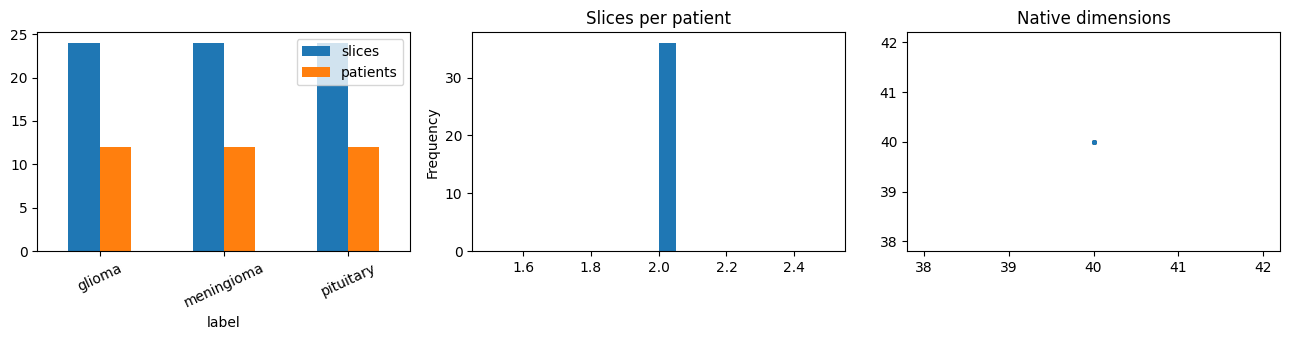

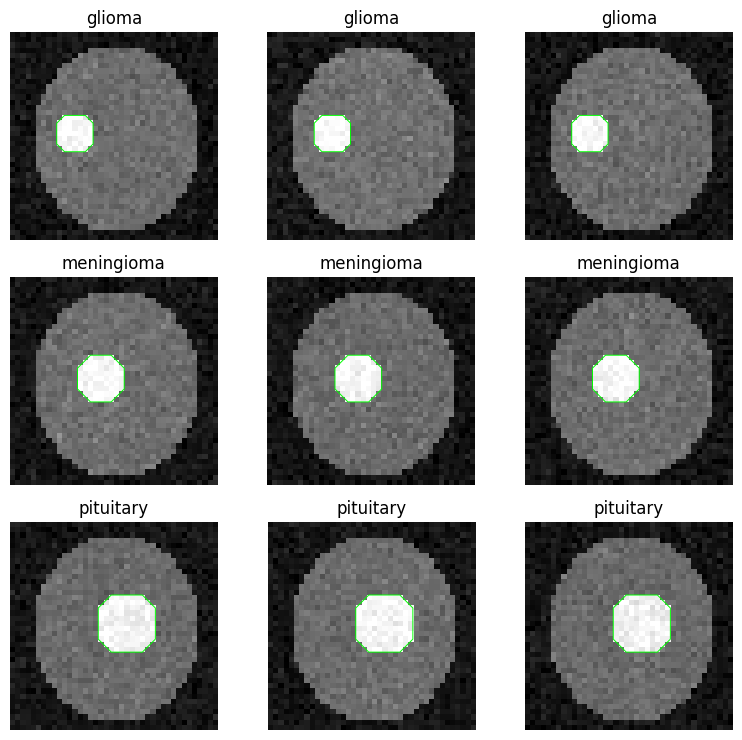

In [16]:
def build_smoke_task4(directory):
    """Build tiny, frozen synthetic artifacts with the original nested engine.

    This function is never entered for paper. It does not synthesize completion
    flags for real experiments or use an outer-test patient during fitting.
    """
    global OUT, PROTOCOL_SHA
    if PROFILE != 'smoke':
        raise RuntimeError('Synthetic fixture creation is allowed only in smoke mode.')
    directory = Path(directory)
    completion = directory/'completion.json'
    if completion.is_file():
        return directory
    directory.mkdir(parents=True, exist_ok=True)
    previous_out = OUT
    had_protocol = 'PROTOCOL_SHA' in globals()
    previous_protocol = globals().get('PROTOCOL_SHA')
    OUT = directory
    try:
        print('Building synthetic Task 4 fixtures (CPU, 36 patients / 72 images).')
        frame = patient_duplicate_links(native_manifest())
        plans = make_nested_plan(frame)
        frame.to_csv(directory/'manifest.csv', index=False)
        write_json(directory/'nested_plan.json', plans)
        # Nine synthetic patients, three from each class, exercise subset outputs.
        legacy_ids = sorted(frame.groupby('label_id')['patient_id'].unique().map(lambda x: sorted(x)[:3]).explode())
        write_json(directory/'legacy_test_patients.json', dict(patient_ids=legacy_ids,
            membership_status='Synthetic nine-patient test fixture; not the historical MRI holdout.'))
        protocol = dict(task=4, profile='smoke', engine_signature=ENGINE_SIGNATURE,
            cfg=CFG, views=VIEWS, split_seed=SPLIT_SEED, fixture=True,
            fixture_origin='task2-self-contained-smoke-v2',
            manifest_sha256=file_hash(directory/'manifest.csv'),
            plan_sha256=file_hash(directory/'nested_plan.json'))
        PROTOCOL_SHA = digest(protocol)
        write_json(directory/'protocol.json', protocol)
        original_math_checks().to_csv(directory/'circuit_math_checks.csv', index=False)
        features = feature_arrays(frame)
        bundles = [nested_fold(frame, features, plan, view) for view in VIEWS for plan in plans]
        evaluate_nested_bundles(frame, features, bundles)
        write_json(completion, dict(task=4, profile='smoke', fixture=True,
            fixture_origin=protocol['fixture_origin'], protocol_sha256=PROTOCOL_SHA,
            manifest_sha256=file_hash(directory/'manifest.csv'),
            plan_sha256=file_hash(directory/'nested_plan.json')))
        return directory
    finally:
        OUT = previous_out
        if had_protocol:
            PROTOCOL_SHA = previous_protocol
        else:
            globals().pop('PROTOCOL_SHA', None)


def resolve_task4_directory(results_root, run_name, override='', alternate_roots=None):
    expected = Path(results_root).expanduser()/'task4'/run_name
    if override:
        selected = Path(override).expanduser().resolve()
        if not (selected/'completion.json').is_file():
            raise FileNotFoundError('TASK4_RESULTS_DIR must contain completion.json and the complete '
                'saved Task 4 artifacts: '+str(selected))
        return selected
    if (expected/'completion.json').is_file():
        return expected.resolve()
    # Smoke fixtures are local to this configured root; never silently borrow
    # a different experiment from another notebook/session.
    if PROFILE == 'smoke' and SMOKE_AUTO_BUILD_TASK4:
        return build_smoke_task4(expected).resolve()
    if alternate_roots is None:
        alternate_roots = [Path('/content/Brain_MRI_Faculty_Revision'),
            Path('/content/drive/MyDrive/Brain_MRI_Faculty_Revision'),
            Path.cwd()/'Brain_MRI_Faculty_Revision']
    roots = list(dict.fromkeys(Path(p).expanduser().resolve() for p in [results_root,*alternate_roots]))
    candidates = [r/'task4'/run_name for r in roots if (r/'task4'/run_name/'completion.json').is_file()]
    if len(candidates) == 1:
        print('Loading Task 4 from:', candidates[0])
        return candidates[0]
    if len(candidates) > 1:
        raise ValueError('Multiple Task 4 runs match. Set TASK4_RESULTS_DIR to one exact folder:\n' +
                         '\n'.join(map(str,candidates)))
    raise FileNotFoundError('Task 4 files are missing. Expected '+str(expected)+
        '. Restore the complete Task4_<run>.zip (including all fold bundles), or finish Task 4. '
        'Set TASK4_RESULTS_DIR to the folder containing completion.json and match PROFILE and '
        'TASK4_RUN_NAME. Use PROFILE=smoke for a standalone synthetic test.')


TASK4_DIR = resolve_task4_directory(ROOT, TASK4_RUN_NAME, TASK4_RESULTS_DIR)
TASK4_COMPLETION = json.loads((TASK4_DIR/'completion.json').read_text())
if TASK4_COMPLETION.get('task') != 4 or TASK4_COMPLETION.get('profile') != PROFILE:
    raise ValueError('Task 4 task/profile mismatch. Match Configuration to the completed run; '
                     'smoke and paper artifacts cannot be mixed.')
required = ['protocol.json','nested_plan.json','manifest.csv','legacy_test_patients.json',
            'slice_oof_predictions.csv']
missing = [name for name in required if not (TASK4_DIR/name).is_file()]
if missing:
    raise FileNotFoundError('Incomplete Task 4 result at '+str(TASK4_DIR)+': '+', '.join(missing))
TASK4_PROTOCOL = json.loads((TASK4_DIR/'protocol.json').read_text())
if digest(TASK4_PROTOCOL) != TASK4_COMPLETION.get('protocol_sha256'):
    raise ValueError('Task 4 protocol hash mismatch; restore its matching complete results.')
if TASK4_PROTOCOL.get('profile') != PROFILE or TASK4_PROTOCOL.get('engine_signature') != ENGINE_SIGNATURE:
    raise ValueError('Task 4 profile/engine differs. Use compatible notebooks and matching profiles.')
if PROFILE == 'paper' and (TASK4_PROTOCOL.get('fixture') or TASK4_COMPLETION.get('fixture')):
    raise ValueError('Synthetic fixtures cannot be used for paper results.')
for name,key in [('manifest.csv','manifest_sha256'),('nested_plan.json','plan_sha256')]:
    if file_hash(TASK4_DIR/name) != TASK4_COMPLETION.get(key):
        raise ValueError('Task 4 '+name+' hash mismatch. Restore the original matching artifact.')
CFG = TASK4_PROTOCOL['cfg']; VIEWS = TASK4_PROTOCOL['views']; SPLIT_SEED = TASK4_PROTOCOL['split_seed']
if not VIEWS or len(set(VIEWS)) != len(VIEWS) or not set(VIEWS) <= {'pixels32','resnet18'}:
    raise ValueError('Task 4 contains unsupported or duplicate feature views.')
if not CFG.get('seeds') or len(set(CFG['seeds'])) != len(CFG['seeds']) or int(CFG.get('bootstrap',0)) < 2:
    raise ValueError('Task 4 needs unique seeds and at least two bootstrap draws.')
PLANS = json.loads((TASK4_DIR/'nested_plan.json').read_text())
if not PLANS or len({p['fold'] for p in PLANS}) != len(PLANS):
    raise ValueError('Task 4 nested plan is empty or has duplicate folds.')
missing_bundles = [str(TASK4_DIR/view/f"fold_{plan['fold']:02d}"/'bundle.joblib')
    for view in VIEWS for plan in PLANS
    if not (TASK4_DIR/view/f"fold_{plan['fold']:02d}"/'bundle.joblib').is_file()]
if missing_bundles:
    raise FileNotFoundError('Restore the missing Task 4 fold bundles:\n'+'\n'.join(missing_bundles))
FRAME = pd.read_csv(TASK4_DIR/'manifest.csv', dtype={'sample_id':str,'patient_id':str,'split_group':str})
required_cols = {'sample_id','patient_id','label_id','label','path','split_group','file_sha256'}
if not required_cols <= set(FRAME.columns) or FRAME.empty or not FRAME['sample_id'].is_unique:
    raise ValueError('Task 4 manifest is empty, incomplete or has duplicate sample IDs.')
if FRAME[list(required_cols)].isna().any().any() or FRAME.groupby('patient_id')['label_id'].nunique().max() != 1:
    raise ValueError('Task 4 manifest has missing values or conflicting patient labels.')
if FRAME.groupby('patient_id')['split_group'].nunique().max() != 1:
    raise ValueError('A patient belongs to more than one linked cluster.')
if not all(Path(p).is_file() for p in FRAME['path']):
    refreshed = native_manifest().set_index('sample_id')
    for i,row in FRAME.iterrows():
        if row.sample_id not in refreshed.index or refreshed.at[row.sample_id,'file_sha256'] != row.file_sha256:
            raise ValueError('Native dataset differs from Task 4 for sample '+row.sample_id)
        FRAME.at[i,'path'] = refreshed.at[row.sample_id,'path']
for row in FRAME.itertuples():
    if file_hash(row.path) != row.file_sha256:
        raise ValueError('Native MAT bytes changed for sample '+row.sample_id+'. Restore the original file.')
test_ids = [pid for plan in PLANS for pid in plan['test_patients']]
if len(test_ids) != len(set(test_ids)) or set(test_ids) != set(FRAME['patient_id']):
    raise ValueError('Outer test folds must partition every patient exactly once.')
for plan in PLANS:
    dev, test = set(plan['development_patients']), set(plan['test_patients'])
    if dev & test or dev | test != set(FRAME['patient_id']):
        raise ValueError('Outer development/test membership is invalid for fold '+str(plan['fold']))
    dev_groups = set(FRAME.loc[FRAME['patient_id'].isin(dev),'split_group'])
    test_groups = set(FRAME.loc[FRAME['patient_id'].isin(test),'split_group'])
    if dev_groups & test_groups:
        raise ValueError('Linked patients cross an outer train/test boundary.')
LEGACY = json.loads((TASK4_DIR/'legacy_test_patients.json').read_text())
LEGACY_IDS = set(LEGACY['patient_ids'])
if not LEGACY_IDS <= set(FRAME['patient_id']):
    raise ValueError('Historical subset includes unknown patients.')
TASK4_SLICES = pd.read_csv(TASK4_DIR/'slice_oof_predictions.csv', dtype={'sample_id':str,'patient_id':str})
keys = ['view','fold','seed','model','sample_id']
if not set(keys+['patient_id','label_id']+[f'p{j}' for j in range(K)]) <= set(TASK4_SLICES.columns):
    raise ValueError('Task 4 slice predictions are missing required columns.')
if TASK4_SLICES.duplicated(keys).any():
    raise ValueError('Task 4 slice predictions contain duplicate keys.')
FRAME.to_csv(OUT/'manifest.csv', index=False)
write_json(OUT/'protocol.json', dict(task=2, profile=PROFILE, engine_signature=ENGINE_SIGNATURE,
    implementation=OCCLUSION_IMPLEMENTATION, task4_protocol=TASK4_COMPLETION['protocol_sha256'],
    all_slices=True, mask_intervention='after fixed clean normalization before resize',
    translation='no wrapping or clipping; equal area; zero tumor overlap; image-only placement',
    bootstrap=CFG['bootstrap']))
print('Verified Task 4:', TASK4_DIR, '| profile:', PROFILE)
print('Patients:', FRAME['patient_id'].nunique(), '| slices:', len(FRAME), '| subset patients:', len(LEGACY_IDS))
dataset_eda(FRAME)

## Native mask checks and displaced control masks

In [17]:
from scipy.signal import fftconvolve
from scipy.ndimage import label as connected_components, binary_closing

def displaced_control(clean,mask):
    if mask.shape!=clean.shape or not mask.any() or mask.all():raise ValueError('Empty/full/unaligned tumor mask')
    # A true translation: no np.roll wrapping, no clipping or changing the masked area.
    yy,xx=np.where(mask);y0,x0=yy.min(),xx.min();crop=mask[yy.min():yy.max()+1,xx.min():xx.max()+1]
    foreground=clean>.05
    labels,n=connected_components(foreground)
    if n:
        counts=np.bincount(labels.ravel());counts[0]=0;foreground=labels==counts.argmax()
    foreground=binary_fill_holes(binary_closing(foreground,iterations=2))
    area=int(mask.sum());kernel=crop[::-1,::-1].astype(float)
    overlap=fftconvolve(mask.astype(float),kernel,mode='valid')
    tissue=fftconvolve(foreground.astype(float),kernel,mode='valid')/area
    mean_signal=fftconvolve(clean.astype(float),kernel,mode='valid')/area
    py,px=np.indices(overlap.shape);distance=np.sqrt((py-y0)**2+(px-x0)**2)
    valid=(overlap<.5)&(distance>=max(2.,.5*math.sqrt(area/np.pi)))
    if not valid.any():raise ValueError('No nonoverlapping, area-preserving displaced mask fits. This image is explicitly unresolved; no replacement or silent exclusion.')
    # Choose tissue coverage first, then similar mean intensity, then shorter displacement.
    # All choices are image/mask based and fixed before looking at model predictions.
    max_tissue=float(tissue[valid].max());candidates=valid&(tissue>=max_tissue-.005)
    desired=float(clean[mask].mean());cost=abs(mean_signal-desired)+1e-5*distance
    cost[~candidates]=np.inf;top,left=np.unravel_index(np.argmin(cost),cost.shape)
    out=np.zeros_like(mask);out[top:top+crop.shape[0],left:left+crop.shape[1]]=crop
    assert out.sum()==mask.sum() and not np.logical_and(out,mask).any()
    return out,dict(displacement_y=int(top-y0),displacement_x=int(left-x0),control_foreground_fraction=float(foreground[out].mean()),
        tumor_foreground_fraction=float(foreground[mask].mean()),control_area=int(out.sum()),tumor_area=area,
        tumor_control_intersection=int(np.logical_and(out,mask).sum()),control_low_tissue_coverage=bool(foreground[out].mean()<.90))

def occlusion_variants(row):
    raw,mask,pid,label,fields=read_mat(row.path)
    if mask is None or not mask.any():raise ValueError('Missing/empty tumorMask: '+row.path)
    assert pid==row.patient_id and label==row.label
    clean=normalize_image(raw);control,qc=displaced_control(clean,mask)
    outside=(clean>.05)&~mask&~control
    fill=float(np.median(clean[outside])) if outside.any() else float(np.median(clean))
    tumor=clean.copy();displaced=clean.copy();tumor[mask]=fill;displaced[control]=fill
    assert np.array_equal(tumor[~mask],clean[~mask]) and np.array_equal(displaced[~control],clean[~control])
    qc.update(sample_id=row.sample_id,patient_id=pid,label_id=int(row.label_id),mask_field_present='tumorMask' in fields,
        native_height=raw.shape[0],native_width=raw.shape[1],fill_value=fill,tumor_fraction=float(mask.mean()),
        original_45=pid in LEGACY_IDS)
    return clean,tumor,displaced,mask,control,qc


## Run all slices using their saved outer-fold models

In [18]:
def validate_fold_cache(cached, identity, view, fold, part):
    if not isinstance(cached,dict) or cached.get('identity') != identity:
        return False
    records=pd.DataFrame(cached.get('rows',[]));qc=pd.DataFrame(cached.get('qc',[]))
    required={'view','fold','seed','model','sample_id','patient_id','label_id','original_45',
        'clean_reproduction_max_error','tumor_probability_drop','control_probability_drop',
        'tumor_minus_control_drop'} | {f'{condition}_p{j}' for condition in ['clean','tumor','control'] for j in range(K)}
    if records.empty or not required <= set(records.columns) or qc.empty:
        return False
    chosen={'Coherent5','Passive5','QuadraticLift_LR','SelectedClassical'}
    expected_keys={(seed,model) for seed in CFG['seeds'] for model in chosen}
    if set(zip(records['seed'],records['model'])) != expected_keys:
        return False
    if not records['view'].eq(view).all() or not records['fold'].eq(fold).all():
        return False
    if records.duplicated(['seed','model','sample_id']).any():
        return False
    if any(set(s['sample_id']) != set(part['sample_id']) for _,s in records.groupby(['seed','model'])):
        return False
    expected=part.set_index('sample_id').loc[records['sample_id']]
    if not np.array_equal(records['patient_id'].to_numpy(),expected['patient_id'].to_numpy()) or not np.array_equal(records['label_id'].to_numpy(),expected['label_id'].to_numpy()):
        return False
    if not records['original_45'].isin([True,False]).all() or not np.array_equal(records['original_45'].to_numpy(),records['patient_id'].isin(LEGACY_IDS).to_numpy()):
        return False
    if not {'view','sample_id','mask_field_present','control_area','tumor_area',
        'tumor_control_intersection','control_foreground_fraction','tumor_fraction',
        'control_low_tissue_coverage'} <= set(qc.columns):
        return False
    if qc.duplicated(['view','sample_id']).any() or set(qc['sample_id']) != set(part['sample_id']):
        return False
    if not qc['view'].eq(view).all() or not qc['mask_field_present'].eq(True).all():
        return False
    if not (qc['control_area'].eq(qc['tumor_area']) & qc['tumor_area'].gt(0) & qc['tumor_control_intersection'].eq(0)).all():
        return False
    for col in ['control_foreground_fraction','tumor_fraction']:
        values=qc[col].to_numpy(float)
        if not np.isfinite(values).all() or (values<0).any() or (values>1).any():
            return False
    probabilities={}
    for condition in ['clean','tumor','control']:
        p=records[[f'{condition}_p{j}' for j in range(K)]].to_numpy(float)
        if not np.isfinite(p).all() or (p<0).any() or not np.allclose(p.sum(1),1,atol=1e-6):
            return False
        probabilities[condition]=p[np.arange(len(records)),records['label_id'].to_numpy(int)]
    expected_drops={'tumor_probability_drop':probabilities['clean']-probabilities['tumor'],
        'control_probability_drop':probabilities['clean']-probabilities['control'],
        'tumor_minus_control_drop':probabilities['control']-probabilities['tumor']}
    if any(not np.allclose(records[key].to_numpy(float),value,atol=1e-12,rtol=1e-10) for key,value in expected_drops.items()):
        return False
    return np.isfinite(records['clean_reproduction_max_error']).all() and records['clean_reproduction_max_error'].lt(1e-4 if view=='resnet18' else 1e-8).all()

def run_full_occlusion():
    rows=[];qc_rows=[];plot_count=0
    for view in VIEWS:
        for plan in PLANS:
            fold=plan['fold'];bundle_path=TASK4_DIR/view/f'fold_{fold:02d}'/'bundle.joblib'
            if not bundle_path.exists():raise FileNotFoundError('Complete Task 4 first: '+str(bundle_path))
            bundle=joblib.load(bundle_path)
            if bundle.get('protocol_sha256')!=TASK4_COMPLETION['protocol_sha256']:
                raise ValueError('Fold bundle belongs to a different Task 4 protocol: '+str(bundle_path))
            if bundle.get('view')!=view or bundle.get('fold')!=fold:
                raise ValueError('Fold bundle is in the wrong representation/fold folder: '+str(bundle_path))
            if set(bundle['test_patients'])!=set(plan['test_patients']) or set(bundle['development_patients'])!=set(plan['development_patients']):
                raise ValueError('Fold bundle patient membership differs from the saved nested plan.')
            if set(bundle['development_patients'])&set(plan['test_patients']):
                raise ValueError('A fold model was developed using its outer-test patient.')
            if set(bundle['models'])!=set(CFG['seeds']):
                raise ValueError('Fold bundle seeds differ from the completed Task 4 protocol.')
            ii=idx_for(FRAME,plan['test_patients']);part=FRAME.iloc[ii]
            cp=OUT/f'occlusion_{view}_fold_{fold:02d}.joblib'
            cache_id=digest(dict(task4=bundle['identity'],mask_version=OCCLUSION_IMPLEMENTATION,scope='all_outer_test_slices',seeds=CFG['seeds'],manifest=file_hash(OUT/'manifest.csv'),bundle_sha256=file_hash(bundle_path),reference_sha256=file_hash(TASK4_DIR/'slice_oof_predictions.csv')))
            if cp.exists():
                try:
                    cached=joblib.load(cp)
                    valid_cache=validate_fold_cache(cached,cache_id,view,fold,part)
                except Exception as exc:
                    print('Recomputing unreadable cache:',cp.name,'('+type(exc).__name__+')')
                    valid_cache=False
                if valid_cache:
                    print('Resume validated occlusion:',view,'fold',fold)
                    rows.extend(cached['rows']);qc_rows.extend(cached['qc']);continue
                print('Recomputing stale/incomplete occlusion cache:',cp.name)
            clean=[];tumor=[];control=[];local_qc=[]
            for r in tqdm(part.itertuples(),total=len(part),desc=f'{view} fold{fold} native occlusion'):
                a,b,c,m,cm,qc=occlusion_variants(r);clean.append(a);tumor.append(b);control.append(c);local_qc.append(qc)
                if view==VIEWS[0] and plot_count<3:
                    fig,axs=plt.subplots(1,4,figsize=(10,3))
                    for ax,im,title in zip(axs,[a,b,c,a],['Clean','Tumor occluded','Displaced control','Native masks']):ax.imshow(im,cmap='gray',vmin=0,vmax=1);ax.set_title(title);ax.axis('off')
                    axs[3].contour(m,levels=[.5],colors=['red']);axs[3].contour(cm,levels=[.5],colors=['cyan'])
                    savefig(fig,f'mask_example_{plot_count}');plot_count+=1
            if view=='pixels32':
                raw_sets=[np.stack([resize_float(x,32).ravel() for x in ims]).astype(float) for ims in [clean,tumor,control]]
            elif PROFILE=='smoke':
                projection=np.random.default_rng(411).normal(size=(1024,64))/np.sqrt(1024)
                raw_sets=[np.stack([resize_float(x,32).ravel() for x in ims])@projection for ims in [clean,tumor,control]]
            else:raw_sets=[resnet_features(ims).astype(float) for ims in [clean,tumor,control]]
            prepared=[prep_transform(bundle['prep'],x) for x in raw_sets];local=[]
            chosen=['Coherent5','Passive5','QuadraticLift_LR','SelectedClassical']
            for seed in CFG['seeds']:
                for name in chosen:
                    actual=bundle['selected_classical'] if name=='SelectedClassical' else name
                    model=bundle['models'][seed][actual];ps=[softmax(predict_record(model,d),axis=1) for d in prepared]
                    # The clean path must reproduce Task 4; otherwise the intervention would compare different pipelines.
                    reference=TASK4_SLICES[(TASK4_SLICES['view']==view)&(TASK4_SLICES.fold==fold)&(TASK4_SLICES.seed==seed)&(TASK4_SLICES.model==name)].set_index('sample_id')
                    if not reference.index.is_unique or set(reference.index)!=set(part['sample_id']):
                        raise ValueError(f'Incomplete Task 4 clean reference for {view}/fold {fold}/{seed}/{name}.')
                    if not np.array_equal(reference.loc[part['sample_id'],'patient_id'].to_numpy(),part['patient_id'].to_numpy()):
                        raise ValueError('Task 4 reference patient IDs do not match the manifest.')
                    expected=reference.loc[part['sample_id'],[f'p{j}' for j in range(K)]].to_numpy(float)
                    if not np.isfinite(expected).all() or not np.allclose(expected.sum(1),1,atol=1e-6):
                        raise ValueError('Invalid Task 4 clean reference probabilities.')
                    err=float(np.max(abs(ps[0]-expected)))
                    assert err<(1e-4 if view=='resnet18' else 1e-8), f'Clean-pipeline mismatch {view}/{name}: {err}'
                    for n,r in enumerate(part.itertuples()):
                        y=int(r.label_id);a,b,c=[p[n] for p in ps]
                        record=dict(view=view,fold=fold,seed=seed,model=name,selected_family=actual,sample_id=r.sample_id,patient_id=r.patient_id,label_id=y,
                            original_45=r.patient_id in LEGACY_IDS,clean_true_probability=float(a[y]),tumor_true_probability=float(b[y]),control_true_probability=float(c[y]),
                            tumor_probability_drop=float(a[y]-b[y]),control_probability_drop=float(a[y]-c[y]),
                            tumor_minus_control_drop=float(c[y]-b[y]),clean_reproduction_max_error=err)
                        for condition,p in zip(['clean','tumor','control'],[a,b,c]):
                            record.update({condition+f'_p{j}':float(p[j]) for j in range(K)})
                        local.append(record)
            for q in local_qc:q['view']=view
            atomic_joblib(dict(identity=cache_id,rows=local,qc=local_qc),cp)
            rows.extend(local);qc_rows.extend(local_qc)
    return pd.DataFrame(rows),pd.DataFrame(qc_rows)

## Patient-cluster bootstrap with all models and seeds paired

In [19]:
def occlusion_summary(table,frame):
    required={'view','model','seed','sample_id','patient_id','label_id','original_45',
        'tumor_probability_drop','control_probability_drop','tumor_minus_control_drop'}
    if table.empty:
        return pd.DataFrame(),pd.DataFrame()
    if not required <= set(table.columns):
        raise ValueError('Occlusion summary is missing columns: '+', '.join(sorted(required-set(table.columns))))
    if table.duplicated(['view','seed','model','sample_id']).any():
        raise ValueError('Duplicate slice records would bias the patient summary.')
    effects=[];metrics_rows=[]
    group_map=frame[['patient_id','split_group']].drop_duplicates().set_index('patient_id').split_group
    for scope,source in [('all_233_oof',table),('historical_45_oof_subset',table[table.original_45])]:
        for (view,model),sub in source.groupby(['view','model']):
            if sub.empty:continue
            if set(sub['seed'])!=set(CFG['seeds']):
                raise ValueError(f'Missing paired seeds in {scope}/{view}/{model}.')
            print(f'Bootstrap {scope} / {view} / {model}: {sub.patient_id.nunique()} patients',flush=True)
            patient=sub.groupby(['seed','patient_id','label_id'],as_index=False)[['tumor_probability_drop','control_probability_drop','tumor_minus_control_drop']].mean()
            ids=sorted(patient.patient_id.unique());seeds=CFG['seeds'];ys=patient.drop_duplicates('patient_id').set_index('patient_id').loc[ids].label_id.to_numpy(int)
            if not set(ids)<=set(group_map.index):
                raise ValueError('Summary contains a patient outside the verified manifest.')
            if any(set(s.patient_id)!=set(ids) for _,s in patient.groupby('seed')):
                raise ValueError('Every seed must contain the same paired patients.')
            linked=group_map.loc[ids].to_numpy();ug=np.unique(linked);rng=np.random.default_rng(818)
            arrays={key:np.stack([patient[patient.seed==s].set_index('patient_id').loc[ids,key].to_numpy(float) for s in seeds]) for key in ['tumor_probability_drop','control_probability_drop','tumor_minus_control_drop']}
            draws={k:[] for k in arrays}
            for _ in range(CFG['bootstrap']):
                if len(ug)<len(ids):
                    sampled=rng.choice(ug,len(ug),replace=True);ii=np.concatenate([np.flatnonzero(linked==g) for g in sampled])
                else:ii=stratified_resample(ys,rng)
                ss=rng.integers(0,len(seeds),len(seeds))
                for key,a in arrays.items():draws[key].append(float(a[np.ix_(ss,ii)].mean()))
            for key,a in arrays.items():
                lo,hi=np.quantile(draws[key],[.025,.975])
                effects.append(dict(scope=scope,view=view,model=model,effect=key,estimate=float(a.mean()),ci_low=float(lo),ci_high=float(hi),
                    n_patients=len(ids),n_slices=sub.sample_id.nunique(),n_seeds=len(seeds),
                    interval_scope='patient (or linked-patient cluster) and seed bootstrap; patients equally weighted; conditional on fitted outer folds'))
            # Secondary patient-level classification changes, paired with the probability analysis.
            patient_ps={}
            for condition in ['clean','tumor','control']:
                cols=[condition+f'_p{j}' for j in range(K)]
                grouped=sub.groupby(['seed','patient_id','label_id'])[cols].mean().reset_index()
                pp=np.stack([grouped[grouped.seed==s].set_index('patient_id').loc[ids,cols].to_numpy() for s in seeds]);patient_ps[condition]=pp
                metrics_rows.append(dict(scope=scope,view=view,model=model,condition=condition,mean_macro_f1=np.mean([metric(ys,p)['macro_f1'] for p in pp]),
                    mean_accuracy=np.mean([metric(ys,p)['accuracy'] for p in pp]),n_patients=len(ids)))
            delta=seed_patient_interval(ys,patient_ps['control'],patient_ps['tumor'],n_boot=CFG['bootstrap'],groups=linked if len(ug)<len(ids) else None)
            effects.append(dict(scope=scope,view=view,model=model,effect='control_minus_tumor_macro_f1',n_slices=sub.sample_id.nunique(),**delta))
    return pd.DataFrame(effects),pd.DataFrame(metrics_rows)

## Execute and reconcile complete coverage

Resume validated occlusion: pixels32 fold 0
Resume validated occlusion: pixels32 fold 1
Resume validated occlusion: resnet18 fold 0
Resume validated occlusion: resnet18 fold 1
Bootstrap all_233_oof / pixels32 / Coherent5: 36 patients
Bootstrap all_233_oof / pixels32 / Passive5: 36 patients
Bootstrap all_233_oof / pixels32 / QuadraticLift_LR: 36 patients
Bootstrap all_233_oof / pixels32 / SelectedClassical: 36 patients
Bootstrap all_233_oof / resnet18 / Coherent5: 36 patients
Bootstrap all_233_oof / resnet18 / Passive5: 36 patients
Bootstrap all_233_oof / resnet18 / QuadraticLift_LR: 36 patients
Bootstrap all_233_oof / resnet18 / SelectedClassical: 36 patients
Bootstrap historical_45_oof_subset / pixels32 / Coherent5: 9 patients
Bootstrap historical_45_oof_subset / pixels32 / Passive5: 9 patients
Bootstrap historical_45_oof_subset / pixels32 / QuadraticLift_LR: 9 patients
Bootstrap historical_45_oof_subset / pixels32 / SelectedClassical: 9 patients
Bootstrap historical_45_oof_subset / r

,scope,view,model,effect,estimate,ci_low,ci_high,n_patients,n_slices,n_seeds,interval_scope,patient_only_low,patient_only_high,n_boot,n_observed_classes
0,all_233_oof,pixels32,Coherent5,tumor_probability_drop,0.03527,0.03162,0.03936,36,72,1,patient (or linked-patient cluster) and seed b...,NaN,NaN,NaN,NaN
1,all_233_oof,pixels32,Coherent5,control_probability_drop,0.00232,0.00089,0.00378,36,72,1,patient (or linked-patient cluster) and seed b...,NaN,NaN,NaN,NaN
2,all_233_oof,pixels32,Coherent5,tumor_minus_control_drop,0.03295,0.02883,0.03774,36,72,1,patient (or linked-patient cluster) and seed b...,NaN,NaN,NaN,NaN
3,all_233_oof,pixels32,Coherent5,control_minus_tumor_macro_f1,0.00000,0.00000,0.00000,36,72,1,paired seed and patient/linked-cluster resampl...,0.00000,0.00000,50.0,3.0
4,all_233_oof,pixels32,Passive5,tumor_probability_drop,-0.00311,-0.00767,0.00032,36,72,1,patient (or linked-patient cluster) and seed b...,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,historical_45_oof_subset,resnet18,QuadraticLift_LR,control_minus_tumor_macro_f1,0.58148,0.20034,0.88571,9,18,1,paired seed and patient/linked-cluster resampl...,0.20034,0.88571,50.0,3.0
60,historical_45_oof_subset,resnet18,SelectedClassical,tumor_probability_drop,0.65478,0.64365,0.67048,9,18,1,patient (or linked-patient cluster) and seed b...,NaN,NaN,NaN,NaN
61,historical_45_oof_subset,resnet18,SelectedClassical,control_probability_drop,-0.00185,-0.00428,0.00177,9,18,1,patient (or linked-patient cluster) and seed b...,NaN,NaN,NaN,NaN
62,historical_45_oof_subset,resnet18,SelectedClassical,tumor_minus_control_drop,0.65663,0.64590,0.67375,9,18,1,patient (or linked-patient cluster) and seed b...,NaN,NaN,NaN,NaN


,scope,view,model,condition,mean_macro_f1,mean_accuracy,n_patients
0,all_233_oof,pixels32,Coherent5,clean,0.1667,0.3333,36
1,all_233_oof,pixels32,Coherent5,tumor,0.1667,0.3333,36
2,all_233_oof,pixels32,Coherent5,control,0.1667,0.3333,36
3,all_233_oof,pixels32,Passive5,clean,0.1320,0.1667,36
4,all_233_oof,pixels32,Passive5,tumor,0.3785,0.4722,36
5,all_233_oof,pixels32,Passive5,control,0.1333,0.1667,36
6,all_233_oof,pixels32,QuadraticLift_LR,clean,0.4667,0.5556,36
7,all_233_oof,pixels32,QuadraticLift_LR,tumor,0.1667,0.3333,36
8,all_233_oof,pixels32,QuadraticLift_LR,control,0.4969,0.5556,36
9,all_233_oof,pixels32,SelectedClassical,clean,1.0000,1.0000,36


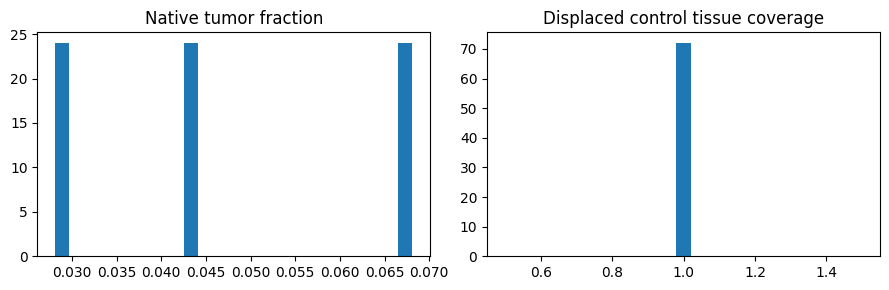

In [20]:
def validate_complete_occlusion(table, qc):
    chosen = {'Coherent5','Passive5','QuadraticLift_LR','SelectedClassical'}
    required = {'view','fold','seed','model','sample_id','patient_id','label_id','original_45',
        'clean_reproduction_max_error','tumor_probability_drop','control_probability_drop',
        'tumor_minus_control_drop'} | {f'{condition}_p{j}' for condition in ['clean','tumor','control'] for j in range(K)}
    if table.empty or not required <= set(table.columns):
        raise ValueError('Occlusion predictions are empty or incomplete. Run the occlusion inference cell.')
    if table.duplicated(['view','seed','model','sample_id']).any():
        raise ValueError('Duplicate slice predictions detected.')
    expected_keys = {(v,s,m) for v in VIEWS for s in CFG['seeds'] for m in chosen}
    if set(zip(table['view'],table['seed'],table['model'])) != expected_keys:
        raise ValueError('Missing or unexpected view/seed/model combinations in occlusion predictions.')
    expected_samples = set(FRAME['sample_id'])
    expected_subset = set(FRAME.loc[FRAME['patient_id'].isin(LEGACY_IDS),'sample_id'])
    identity = FRAME.set_index('sample_id')
    fold_of_patient = {pid:p['fold'] for p in PLANS for pid in p['test_patients']}
    for (view,seed,model), part in table.groupby(['view','seed','model']):
        if set(part['sample_id']) != expected_samples:
            raise ValueError(f'Incomplete all-slice coverage for {view}/{seed}/{model}.')
        if not part['original_45'].isin([True,False]).all():
            raise ValueError('Historical subset flags must be Boolean.')
        if set(part.loc[part['original_45'].eq(True),'sample_id']) != expected_subset:
            raise ValueError('Historical subset coverage differs from its saved patient membership.')
        aligned = identity.loc[part['sample_id']]
        if not np.array_equal(part['patient_id'].to_numpy(),aligned['patient_id'].to_numpy()) or not np.array_equal(part['label_id'].to_numpy(),aligned['label_id'].to_numpy()):
            raise ValueError('Slice identities/labels disagree with the manifest.')
        if not np.array_equal(part['fold'].to_numpy(),part['patient_id'].map(fold_of_patient).to_numpy()):
            raise ValueError('An occlusion prediction came from the wrong outer fold.')
        err = part['clean_reproduction_max_error'].to_numpy(float)
        if not np.isfinite(err).all() or (err >= (1e-4 if view=='resnet18' else 1e-8)).any():
            raise ValueError('The clean predictions do not reproduce frozen Task 4 models.')
        probabilities = {}
        for condition in ['clean','tumor','control']:
            p = part[[f'{condition}_p{j}' for j in range(K)]].to_numpy(float)
            if not np.isfinite(p).all() or (p<0).any() or not np.allclose(p.sum(1),1,atol=1e-6):
                raise ValueError('Nonfinite or invalid probabilities for '+condition)
            probabilities[condition] = p[np.arange(len(part)),part['label_id'].to_numpy(int)]
        expected_drops = {'tumor_probability_drop':probabilities['clean']-probabilities['tumor'],
            'control_probability_drop':probabilities['clean']-probabilities['control'],
            'tumor_minus_control_drop':probabilities['control']-probabilities['tumor']}
        if any(not np.allclose(part[key].to_numpy(float),value,atol=1e-12,rtol=1e-10) for key,value in expected_drops.items()):
            raise ValueError('Saved effect columns do not agree with their prediction probabilities.')
    needed_qc = {'view','sample_id','mask_field_present','control_area','tumor_area',
        'tumor_control_intersection','control_foreground_fraction','tumor_fraction','control_low_tissue_coverage'}
    if qc.empty or not needed_qc <= set(qc.columns) or qc.duplicated(['view','sample_id']).any():
        raise ValueError('Mask quality table is missing, incomplete or duplicated.')
    if set(zip(qc['view'],qc['sample_id'])) != {(v,s) for v in VIEWS for s in expected_samples}:
        raise ValueError('Mask QC does not cover every view and slice.')
    if not qc['mask_field_present'].eq(True).all() or not qc['control_area'].eq(qc['tumor_area']).all() or not qc['tumor_area'].gt(0).all() or not qc['tumor_control_intersection'].eq(0).all():
        raise ValueError('Native masks failed presence, nonempty area or zero-overlap checks.')
    for col in ['control_foreground_fraction','tumor_fraction']:
        values = qc[col].to_numpy(float)
        if not np.isfinite(values).all() or (values<0).any() or (values>1).any():
            raise ValueError('Invalid mask quality values in '+col)
    return True


def atomic_csv(table, path):
    path = Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp = path.with_name(path.name+'.tmp')
    table.to_csv(tmp,index=False); tmp.replace(path)


def execute_task2():
    # A failed rerun must not leave a stale success marker behind.
    (OUT/'completion.json').unlink(missing_ok=True)
    (OUT/'summary_state.json').unlink(missing_ok=True)
    table, qc = run_full_occlusion()
    validate_complete_occlusion(table, qc)
    atomic_csv(table, OUT/'all_slice_occlusion_predictions.csv')
    atomic_csv(qc, OUT/'native_mask_control_quality.csv')
    effects, metrics = occlusion_summary(table, FRAME)
    if effects.empty or metrics.empty:
        raise ValueError('No patient summaries were produced from the verified predictions.')
    atomic_csv(effects, OUT/'patient_paired_occlusion_intervals.csv')
    atomic_csv(metrics, OUT/'patient_occlusion_metrics.csv')
    quality = qc[['view','sample_id','control_foreground_fraction']]
    joined = table.merge(quality,on=['view','sample_id'],validate='many_to_one')
    if len(joined) != len(table):
        raise ValueError('The quality join changed the all-slice prediction coverage.')
    good = joined.loc[joined['control_foreground_fraction']>=.90].copy()
    sensitivity_path = OUT/'secondary_tissue_coverage_ge_090_effects.csv'
    sensitivity_metrics_path = OUT/'secondary_tissue_coverage_ge_090_metrics.csv'
    if len(good) and good['patient_id'].nunique()>=3:
        sensitivity, sensitivity_metrics = occlusion_summary(good,FRAME)
        atomic_csv(sensitivity,sensitivity_path)
        atomic_csv(sensitivity_metrics,sensitivity_metrics_path)
        sensitivity_note = 'Secondary analysis computed from controls with at least 90% tissue coverage.'
    else:
        sensitivity_path.unlink(missing_ok=True)
        sensitivity_metrics_path.unlink(missing_ok=True)
        sensitivity_note = 'Secondary analysis not estimable: fewer than three retained patients.'
    write_json(OUT/'sensitivity_status.json',dict(status=sensitivity_note,
        retained_slices=int(good['sample_id'].nunique()), retained_patients=int(good['patient_id'].nunique())))
    state_files = ['all_slice_occlusion_predictions.csv','native_mask_control_quality.csv',
                   'patient_paired_occlusion_intervals.csv','patient_occlusion_metrics.csv',
                   'sensitivity_status.json']
    if sensitivity_path.is_file():
        state_files += [sensitivity_path.name,sensitivity_metrics_path.name]
    write_json(OUT/'summary_state.json',dict(profile=PROFILE,implementation=OCCLUSION_IMPLEMENTATION,
        task4_protocol=TASK4_COMPLETION['protocol_sha256'],
        files={name:file_hash(OUT/name) for name in state_files}))
    display(effects.round(5)); display(metrics.round(4))
    first = qc.loc[qc['view']==VIEWS[0]]
    fig, axes = plt.subplots(1,2,figsize=(9,3))
    axes[0].hist(first['tumor_fraction'],bins=25); axes[0].set_title('Native tumor fraction')
    axes[1].hist(first['control_foreground_fraction'],bins=25)
    axes[1].set_title('Displaced control tissue coverage')
    savefig(fig,'mask_area_and_control_coverage_eda')
    print('Verified coverage:',len(FRAME),'slices ×',len(VIEWS),'views ×',
          len(CFG['seeds']),'seeds × 4 model comparisons =',len(table),'rows.')
    return table, qc, effects, metrics


OCCLUSION, MASK_QC, EFFECTS, OCC_METRICS = execute_task2()

## Figures and cautious result wording for the paper

Results bundle: /workspace/scratch/a938777b717e/work/smoke_results/task2/Task2_smoke_v1.zip
Report: /workspace/scratch/a938777b717e/work/smoke_results/task2/smoke_v1/TASK2_RESULTS.md
Results ZIP: /workspace/scratch/a938777b717e/work/smoke_results/task2/Task2_smoke_v1.zip


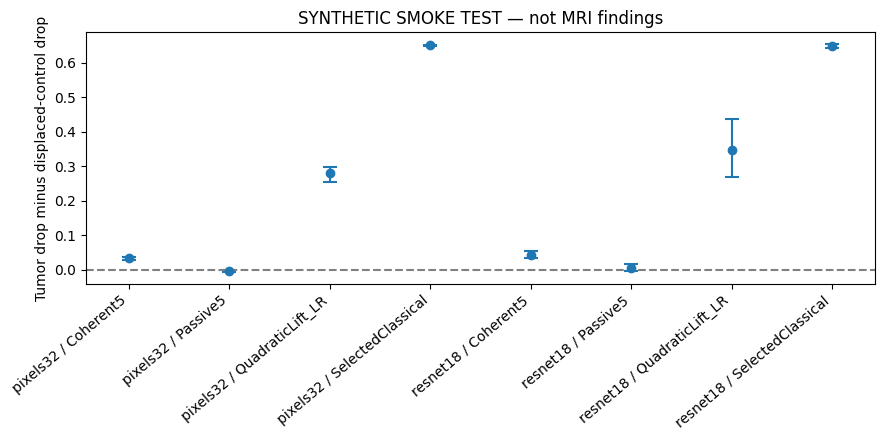

**Task 2 completed:** all slices, frozen clean-prediction reproduction, native mask QC, patient intervals, figures, report and ZIP verified.

In [21]:
def load_verified_task2_summary():
    # Read the files written by execute_task2, so this final cell also works
    # after deleting its in-memory DataFrames or rerunning it on its own.
    state_path = OUT/'summary_state.json'
    if not state_path.is_file():
        raise FileNotFoundError('Run the preceding Execute and reconcile cell first. '
            'It writes validated predictions and summaries to '+str(OUT))
    state = json.loads(state_path.read_text())
    if state.get('profile')!=PROFILE or state.get('implementation')!=OCCLUSION_IMPLEMENTATION or state.get('task4_protocol')!=TASK4_COMPLETION['protocol_sha256']:
        raise ValueError('Saved summaries belong to a different profile/revision/Task 4 run. '
                         'Rerun Execute and reconcile before plotting.')
    expected_files = {'all_slice_occlusion_predictions.csv','native_mask_control_quality.csv',
        'patient_paired_occlusion_intervals.csv','patient_occlusion_metrics.csv','sensitivity_status.json'}
    if not expected_files <= set(state.get('files',{})):
        raise ValueError('Saved summary validation record is incomplete. Rerun Execute and reconcile.')
    for name,expected_hash in state['files'].items():
        if not (OUT/name).is_file() or file_hash(OUT/name)!=expected_hash:
            raise ValueError('Saved summary is missing or changed: '+name+'. Rerun Execute and reconcile.')
    effects = pd.read_csv(OUT/'patient_paired_occlusion_intervals.csv')
    metrics = pd.read_csv(OUT/'patient_occlusion_metrics.csv')
    predictions = pd.read_csv(OUT/'all_slice_occlusion_predictions.csv',dtype={'sample_id':str,'patient_id':str})
    qc = pd.read_csv(OUT/'native_mask_control_quality.csv',dtype={'sample_id':str,'patient_id':str})
    validate_complete_occlusion(predictions,qc)
    required = {'scope','view','model','effect','estimate','ci_low','ci_high'}
    if effects.empty or not required <= set(effects.columns):
        raise ValueError('Saved patient effect intervals are incomplete; rerun Execute and reconcile.')
    if not np.isfinite(effects[['estimate','ci_low','ci_high']].to_numpy(float)).all() or (effects['ci_low']>effects['ci_high']).any():
        raise ValueError('Saved effect intervals are nonfinite or reversed.')
    return predictions,qc,effects,metrics


# Remove success before any plotting/report step that might fail.
(OUT/'completion.json').unlink(missing_ok=True)
OCCLUSION, MASK_QC, EFFECTS, OCC_METRICS = load_verified_task2_summary()
s = EFFECTS.loc[(EFFECTS['scope']=='all_233_oof') &
                (EFFECTS['effect']=='tumor_minus_control_drop')].copy()
expected_pairs = {(v,m) for v in VIEWS for m in ['Coherent5','Passive5','QuadraticLift_LR','SelectedClassical']}
if s.duplicated(['view','model']).any() or set(zip(s['view'],s['model'])) != expected_pairs:
    raise ValueError('Primary figure needs one interval per feature view and model.')
s = s.sort_values(['view','model']).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(max(9,len(s)*1.05),4.5))
xx = np.arange(len(s))
# Draw interval endpoints directly: percentile intervals need not contain the
# point estimate. This also avoids matplotlib negative-yerr exceptions.
ax.vlines(xx,s['ci_low'],s['ci_high'],color='C0',linewidth=1.5)
ax.scatter(xx,s['estimate'],color='C0',zorder=3)
ax.hlines(s['ci_low'],xx-.07,xx+.07,color='C0')
ax.hlines(s['ci_high'],xx-.07,xx+.07,color='C0')
ax.axhline(0,color='gray',ls='--')
ax.set_xticks(xx,(s['view']+' / '+s['model']).tolist(),rotation=40,ha='right')
ax.set_ylabel('Tumor drop minus displaced-control drop')
if PROFILE=='smoke':
    ax.set_title('SYNTHETIC SMOKE TEST — not MRI findings')
savefig(fig,'occlusion_patient_effects')

n_patients = FRAME['patient_id'].nunique()
subset_patients = len(LEGACY_IDS)
first_qc = MASK_QC.loc[MASK_QC['view']==VIEWS[0]]
sensitivity_status = json.loads((OUT/'sensitivity_status.json').read_text())
lines = ['# Task 2 results','']
if PROFILE=='smoke':
    lines += ['**SYNTHETIC ENGINEERING CHECK — no clinical or MRI research conclusions.**',
        f'Test fixture: {n_patients} synthetic patients, {len(FRAME)} synthetic slices, '
        f'{len(VIEWS)} feature paths, {len(CFG["seeds"])} seed(s), four model comparisons.','',
        'The stored scope names all_233_oof and historical_45_oof_subset are compatibility '
        'labels only in smoke mode; their actual sample counts are in each table.','']
else:
    lines += ['Our design choices were informed by data that included the test patients.','']
lines += [
    f'Native cjdata.tumorMask fields, orientation, binary values and nonempty masks were '
    f'checked on every slice. All {len(FRAME)} slices of all {n_patients} outer-test patients '
    f'were processed. The saved subset ({subset_patients} patients) is reported separately '
    'using out-of-fold models. It is not a fresh independent holdout.','',
    'Each displaced control is a nonwrapping translation of the native tumor mask with '
    'exactly equal pixel area and zero tumor overlap. Placement uses only image/mask '
    'information. Tumor and control share a fill value. Tissue coverage is exported for '
    'every slice; large lesions may force controls partly outside the brain.','',
    'Occlusion follows fixed clean-image normalization and precedes resizing/features. '
    'Unmasked normalized pixels remain identical. Models, PCA, norm scaling and '
    'classical family selection remain frozen.','',
    sensitivity_status['status'] + f' Retained slices: {sensitivity_status["retained_slices"]}; '
    f'retained patients: {sensitivity_status["retained_patients"]}. Primary results retain every slice.','',
    'Task 4 softmax decision rules use temperature 1 and have not been independently '
    'probability-calibrated. SVM softmax margins are normalized decision scores. '
    'Comparisons are paired within each model.','',
    'Probability drops are averaged over slices within each patient. Intervals resample '
    'complete patients or linked clusters and complete seeds. Positive tumor-minus-control '
    'drops indicate greater sensitivity to the tumor region. A near-zero estimate with a '
    'wide interval is inconclusive. Macro F1 uses all original labels, including in a '
    'sensitivity subset that omits a class.','',
    EFFECTS.to_markdown(index=False),'',
    'Abstract guidance for the paper profile: report additional tumor sensitivity with '
    'its interval. If intervals remain wide, state that tumor reliance is unresolved. '
    'Occlusion alone cannot establish a causal anatomical mechanism.','',
    'Saved subset membership: '+str(LEGACY.get('membership_status','Status not supplied by Task 4.')),
]
report_path = OUT/'TASK2_RESULTS.md'
report_tmp = report_path.with_suffix('.md.tmp')
report_tmp.write_text('\n'.join(lines),encoding='utf-8'); report_tmp.replace(report_path)
completion = dict(task=2,profile=PROFILE,implementation=OCCLUSION_IMPLEMENTATION,
    task4_protocol=TASK4_COMPLETION['protocol_sha256'],n_patients=int(n_patients),n_slices=len(FRAME),
    n_prediction_rows=len(OCCLUSION),n_views=len(VIEWS),n_seeds=len(CFG['seeds']),
    historical_subset_patients=subset_patients,
    historical_subset_slices=int(FRAME['patient_id'].isin(LEGACY_IDS).sum()),
    complete_all_slice_coverage=True,mask_field_confirmed_for_every_slice=True,
    low_tissue_control_slices=int(first_qc['control_low_tissue_coverage'].sum()),
    synthetic_engineering_check=(PROFILE=='smoke'))
write_json(OUT/'completion.json',completion)
try:
    PACKAGE = package_outputs(OUT,'Task2_'+OUT.name)
except Exception:
    (OUT/'completion.json').unlink(missing_ok=True)
    raise
display(Markdown('**Task 2 completed:** all slices, frozen clean-prediction reproduction, '
    'native mask QC, patient intervals, figures, report and ZIP verified.'))
print('Report:',report_path)
print('Results ZIP:',PACKAGE)

## Outputs, reruns and real data

The final cell prints the report and result ZIP paths. The ZIP includes the
prediction CSV, native-mask QC CSV, paired intervals, patient classification
metrics, figures and protocol records. A secondary tissue-coverage analysis is
explicitly marked unavailable if fewer than three patients remain.

**Rerun:** choose Run all again. Validated fold caches are reused; stale or
incomplete occlusion caches are recomputed. The last cell reloads verified CSVs,
so clearing `EFFECTS` or another output DataFrame does not require inference again.
After a kernel/runtime reset, rerun the setup cells to restore functions and paths.

**Paper profile:** change `PROFILE` to `paper`; match `TASK4_RUN_NAME` and set
`TASK4_RESULTS_DIR` to the completed real Task 4 folder. Restore the entire Task 4
ZIP after a runtime reset, and provide `FIGSHARE_ROOT` if your native MAT files
are already extracted. This notebook verifies the Task 4 hashes, patient folds,
linked clusters and exact clean predictions before accepting real results.
Missing external files and invalid scientific inputs produce specific messages;
they are never replaced with fake paper results. Do not report smoke values.

## Validation of this repaired notebook

All **21 code cells** were executed in order using a CPU IPython session.
The synthetic test processed **36 patients / 72 native MAT images**, two feature
paths, two outer folds, one seed and four model comparisons: **576 prediction
rows**, with **zero execution errors**. Both conventional and HDF5 MATLAB readers
were exercised. Circuit unitarity, gradients and quadratic equivalence passed.

Eight targeted regression checks also passed: complete prediction/QC coverage;
linked-cluster bootstrap with a missing class; single-class subset summaries;
incomplete/tampered cache regeneration; final-cell recovery after clearing result
DataFrames; rejection of changed summaries; missing-paper-artifact handling;
and native-mask translation constraints. A full cached rerun also completed.

**These are synthetic engineering checks.** The real `paper` workflow was not
executed here because the native MRI dataset and trained Task 4 artifacts were
not attached. Change the profile and supply those files for real inference.
